In [317]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import RepeatedKFold,cross_val_score

In [318]:
df_original = pd.read_csv(r"E:\CODING\Numpy_Pandas\house_price_practice\train.csv")
df_original.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [319]:
df = df_original.copy()

In [320]:
print(df.shape)
df.describe()

(1460, 81)


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [321]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

| Column        | What we found                                                          | What we'll do later                                      |
| ------------- | ---------------------------------------------------------------------- | ----------------------------------------------           |
| `Id`          | Unique identifier, 1460/1460                                           | Probably drop                                            |
| `MSSubClass`  | Categorical codes despite being numbers; different price distributions | Treat as categorical → encode later                      |
| `MSZoning`    | 5 categories; price differs between groups                             | OHE later                                                |
| `LotFrontage` | Missing values; varies by neighborhood                                 | Fill missing using neighborhood median                   |
| `LotArea`     | Numerical, strongly right-skewed, extreme values                       | Consider transformation/outlier handling later           |
| `Street`      | 1454 Pave vs 6 Grvl; Pave has higher observed prices                   | Keep for now; encode later                               |
| `Alley`       | NaN means no alley and now we have 3 categories                        | OHE later                                                |
| `LotShape`    | 4 different categories with no missing value                           | Keep as categorical → OHE later                          |
| `LandContour` | 4 different categories with no missing value                           | Keep as categorical → OHE later                          |
| `Utilities`   | extremely imbalenced as only 1/1460 houses has NoSeWa                  | column likely to be removed later for no useful pattern  |
| `LotConfig`   | 5 different categories with no missing value                           | Keep as categorical → OHE later                          |
| `LandSlope`   | 3 categories....gtl->less price...other 2->substantial overlap         | Keep as categorical → OHE later                          |
| `Neighborhood`| SalePrice varies significantly across neighborhoods                    | Keep → OHE later                                         |
| `Condition1`  | 9 categories; SalePrice varies                                         | Keep → OHE later                                         |
| `Condition2`  | extremely imbalanced                                                   | Keep for now, decide later combine/drop rare categories  |
| `BldgType`    |                                                                        | Keep → OHE later                                         |
| `HouseStyle`  |                                                                        | Keep → OHE later                                         |
| `OverallQual` | strong overall positive relation with sale price                       | Keep numeric for now                                     |
| `OverallCond` | relation much weaker than overall qual                                 | Keep numeric for now                                     |
| `YearBuilt`   | clear positive relationship with SalePrice though not fully linear     | Keep numeric for now                                     |
| `RoofStyle`   |                                                                        | OHE later                                                |
| `RoofMatl`    | Categorical and extremely imbalanced. CompShg dominates                | Likely drop later if little benefit                      |
|`Exterior1st/Exterior2nd`| show substantial differences between categories              | likely useful predictors. Keep and OHE later             |
| `MasVnrType`  |                                                                        | keep and OHE later                                       |
| `MasVnrArea`  |                                                                        | Keep as numerical                                        |
| `ExterQual`   | a noticable order was observed Ex > Gd > TA > Fa                       | converted to number according to descending precedence   |
| `ExterCond`   | a noticable order was observed Ex > Gd > TA > Fa > Po                  | converted to number according to descending precedence   |
| `Foundation`  |                                                                        | keep and OHE later                                       |
| `BsmtQual`    | a noticable order was observed Ex > Gd > TA > Fa > None                | converted to number according to descending precedence   |
| `BsmtCond`    | a noticable order was observed Gd > TA > Fa > Po > None                | converted to number according to descending precedence   |
| `BsmtExposure`| a noticable order was observed Gd > Av > Mn > (No + NaN = No)          | converted to number according to descending precedence   |
| `BsmtFinType1`| a noticable order was observed GLQ > ALQ > BLQ > Rec > LwQ > Unf > None| converted to number according to descending precedence   |
| `BsmtFinSF1`  | Positive but noisy relationship with SalePrice                         | Keep as numeric; investigate extreme outliers later.     |
| `BsmtFinType2`| a noticable order was observed GLQ > ALQ > BLQ > Rec > LwQ > Unf > None| converted to number according to descending precedence   |
| `BsmtFinSF2`  | weak/no clear relationship with SalePrice                              | Keep numeric for now; candidate to drop                  |
| `BsmtUnfSF`   | weak/moderate positive relationship with SalePrice, but noisy          | Keep numeric; let model validation determine usefulness  |
| `TotalBsmtSF` | Strong positive relationship with SalePrice                            | Keep numeric                                             |
| `Heating`     | Highly imbalanced                                                      | keep and OHE later or drop based on model validation     |
| `HeatingQC`   | a noticable order was observed Po < Fa < TA < Gd < Ex                  | converted to number according to descending precedence   |
| `CentralAir`  | turn Y and N to 1,0 since binary categorical                           | No need for OHE for just 2 categories                    |
| `Electrical`  |                                                                        | keep and OHE later                                       |
| `1stFlrSF`    | Strong positive relationship with SalePrice                            | Keep numeric                                             |
| `2ndFlrSF`    | Positive but noisy relationship with SalePrice                         | Keep numeric                                             |
| `LowQualFinSF`| mostly 0 with weak relationship to SalePrice                           | strong drop candidate                                    |
| `GrLivArea`   | Strong positive relationship with SalePrice                            | keep numeric                                             |
| `BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr`|               | keep numeric                                             |
| `KitchenQual` | a noticable order was observed Ex > Gd > TA > Fa                       | converted to number according to descending precedence   |
| `TotRmsAbvGrd`| Positive relationship with SalePrice                                   | keep numeric                                             |
| `Functional`  | maj=5,sev=1 but we let model evaluation decide whether to keep them later |                keep and OHE later                     |
| `Fireplaces`  |                                                                        | keep numeric                                             |
| `FireplaceQu` | a noticable order was observed Po < Fa < TA < Gd < Ex                  | converted to number according to descending precedence   |
| `GarageType`  |                                                                        | Keep → OHE later                                         |
| `GarageFinish`| a noticable order was observed None < unf < frn < fin                  | converted to number according to descending precedence   |
| `GarageCars`  |                                                                        | Keep as numerical                                        |
| `GarageArea`  | Positive relationship with SalePrice                                   | keep numeric                                             |
| `GarageQual,GarageCond` | a noticable order was observed Po < Fa < TA < Gd < Ex        | converted to number according to descending precedence   |
| `PavedDrive`  | a noticable order was observed N < P < Y                               | converted to number according to descending precedence   |
| `WoodDeckSF,OpenPorchSF`| positive but noisy relationship with Sale price              | Keep as numerical                                        |
|`EnclosedPorch`| Weak/noisy relationship with SalePrice                                 | Keep as numerical;candidate for removing after validation|
| `3SsnPorch`   |                                                                        | Candidate for dropping                                   |
| `ScreenPorch` |                                                                        | Keep numeric; candidate for dropping after validation    |
| `PoolArea`    |                                                                        | Very strong candidate for dropping                       |
| `Fence`       | though it seems like a relation but it's not..so, no ordinal encoding  | keep and OHE later                                       |
| `MiscFeature` |                                                                        | keep and OHE later                                       |
| `MiscVal`     |                                                                        | Keep numeric; candidate for dropping after validation    |
| `MoSold`      |                                                                        | drop candidate                                           |
| `YrSold`      |                                                                        | keep for now                                             |
| `SaleType`    |                                                                        | keep and OHE later                                       |
|`SaleCondition`|                                                                        | keep and OHE later                                       |

ID(helps us with no information regarding the saleprice....so we drop it....because the machiene might misinterpret it as higher id=higher price)
--but we will only ever do that in the df_copy() after cleaning the rest since we don't want to lose any data permanently

MSSubClass(we check relation with sale price and the rest left for encoding later)

In [322]:
df['MSSubClass'].value_counts()

MSSubClass
20     536
60     299
50     144
120     87
30      69
160     63
70      60
80      58
90      52
190     30
85      20
75      16
45      12
180     10
40       4
Name: count, dtype: int64

In [323]:
df.groupby('MSSubClass')['SalePrice'].mean()

MSSubClass
20     185224.811567
30      95829.724638
40     156125.000000
45     108591.666667
50     143302.972222
60     239948.501672
70     166772.416667
75     192437.500000
80     169736.551724
85     147810.000000
90     133541.076923
120    200779.080460
160    138647.380952
180    102300.000000
190    129613.333333
Name: SalePrice, dtype: float64

MSZoning

In [324]:
df['MSZoning'].value_counts()

MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64

In [325]:
df.groupby('MSZoning')['SalePrice'].mean().sort_values(ascending=False)

MSZoning
FV         214014.061538
RL         191004.994787
RH         131558.375000
RM         126316.830275
C (all)     74528.000000
Name: SalePrice, dtype: float64

LotFrontage
--right now this might have a relation with the neighborhood the house is in...so we check that
--we also try to visually see whether it has a direct relation with the sale price
--we have filled the missing NaN values with the median LotFrontage of that certain neighborhood the house belongs to

In [326]:
df['LotFrontage'].describe()

count    1201.000000
mean       70.049958
std        24.284752
min        21.000000
25%        59.000000
50%        69.000000
75%        80.000000
max       313.000000
Name: LotFrontage, dtype: float64

In [327]:
df.groupby('Neighborhood')['LotFrontage'].median().sort_values()

Neighborhood
BrDale     21.0
MeadowV    21.0
NPkVill    24.0
Blueste    24.0
Blmngtn    43.0
BrkSide    52.0
IDOTRR     60.0
OldTown    60.0
SWISU      60.0
StoneBr    61.5
Gilbert    65.0
Edwards    65.5
SawyerW    66.5
Veenker    68.0
CollgCr    70.0
Sawyer     71.0
NAmes      73.0
Mitchel    73.0
Somerst    73.5
Crawfor    74.0
ClearCr    80.0
NWAmes     80.0
Timber     85.0
NridgHt    88.5
NoRidge    91.0
Name: LotFrontage, dtype: float64

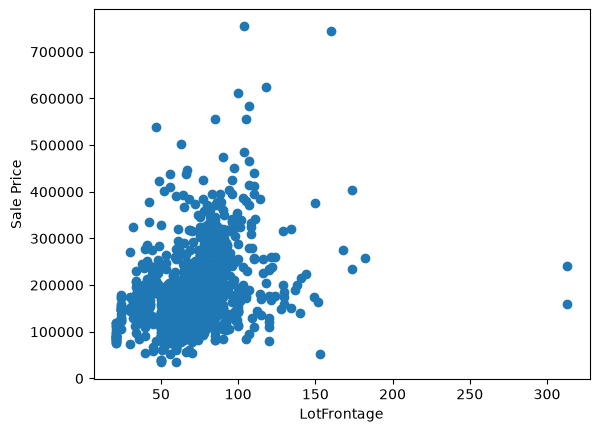

In [328]:
plt.scatter(df['LotFrontage'],df['SalePrice'])
plt.xlabel('LotFrontage')
plt.ylabel('Sale Price')
plt.show()

In [329]:
df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(lambda x:x.fillna(x.median()))
df['LotFrontage'].head(20)

0     65.0
1     80.0
2     68.0
3     60.0
4     84.0
5     85.0
6     75.0
7     80.0
8     51.0
9     50.0
10    70.0
11    85.0
12    71.0
13    91.0
14    73.0
15    51.0
16    73.0
17    72.0
18    66.0
19    70.0
Name: LotFrontage, dtype: float64

LotArea

In [330]:
df['LotArea'].describe()

count      1460.000000
mean      10516.828082
std        9981.264932
min        1300.000000
25%        7553.500000
50%        9478.500000
75%       11601.500000
max      215245.000000
Name: LotArea, dtype: float64

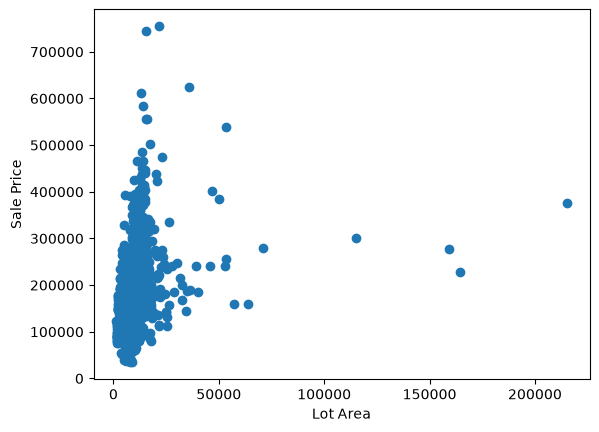

In [331]:
plt.scatter(df['LotArea'],df['SalePrice'])
plt.xlabel('Lot Area')
plt.ylabel('Sale Price')
plt.show()

Streets

In [332]:
df['Street'].value_counts()

Street
Pave    1454
Grvl       6
Name: count, dtype: int64

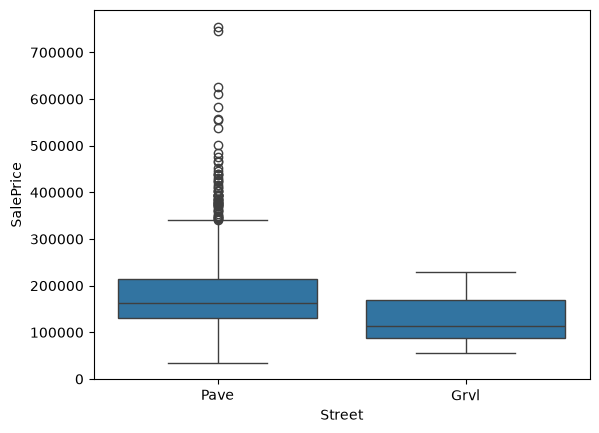

In [333]:
sns.boxplot(
    data=df,
    x=df['Street'],
    y=df['SalePrice']
)
plt.show()

Alley
--we initially did a boxplot but that doesn't seem quite useful since we could only consider 91/1460 values while plotting it
--the NaN here technically doesn't mean that data is missing but instead the house itself might just not have an alley
--so we can technically turn it into a 3rd category later for encoding

In [334]:
df['Alley'].value_counts()

Alley
Grvl    50
Pave    41
Name: count, dtype: int64

In [335]:
df['Alley'] = df['Alley'].fillna('Absent')
df['Alley']

0       Absent
1       Absent
2       Absent
3       Absent
4       Absent
         ...  
1455    Absent
1456    Absent
1457    Absent
1458    Absent
1459    Absent
Name: Alley, Length: 1460, dtype: str

In [336]:
df.groupby('Alley')['SalePrice'].mean().sort_values(ascending=False)

Alley
Absent    183452.131483
Pave      168000.585366
Grvl      122219.080000
Name: SalePrice, dtype: float64

LotShape

In [337]:
df['LotShape'].value_counts()

LotShape
Reg    925
IR1    484
IR2     41
IR3     10
Name: count, dtype: int64

In [338]:
df.groupby('LotShape')['SalePrice'].mean().sort_values(ascending=False)

LotShape
IR2    239833.365854
IR3    216036.500000
IR1    206101.665289
Reg    164754.818378
Name: SalePrice, dtype: float64

<Axes: xlabel='LotShape', ylabel='SalePrice'>

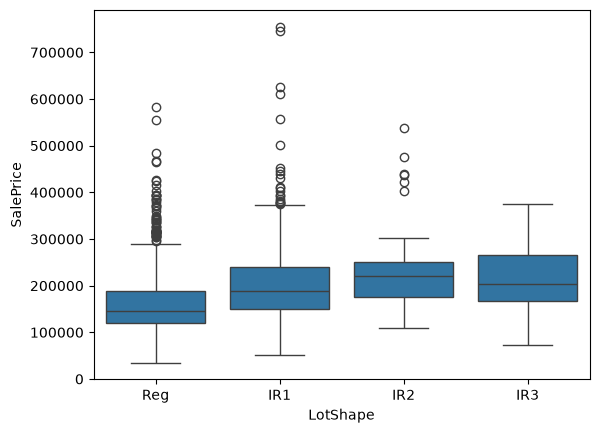

In [339]:
sns.boxplot(
    data=df,
    x=df['LotShape'],
    y=df['SalePrice']
)

LandContour

In [340]:
df['LandContour'].value_counts()

LandContour
Lvl    1311
Bnk      63
HLS      50
Low      36
Name: count, dtype: int64

In [341]:
df.groupby('LandContour')['SalePrice'].mean().sort_values(ascending=False)

LandContour
HLS    231533.940000
Low    203661.111111
Lvl    180183.746758
Bnk    143104.079365
Name: SalePrice, dtype: float64

Utilities

In [342]:
df['Utilities'].value_counts()

Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64

LotConfig

In [343]:
df['LotConfig'].value_counts()

LotConfig
Inside     1052
Corner      263
CulDSac      94
FR2          47
FR3           4
Name: count, dtype: int64

In [344]:
df.groupby('LotConfig')['SalePrice'].mean().sort_values(ascending=False)

LotConfig
CulDSac    223854.617021
FR3        208475.000000
Corner     181623.425856
FR2        177934.574468
Inside     176938.047529
Name: SalePrice, dtype: float64

LandSlope
--we can see that the rarer slopes atre more expensive by the mean
--but to conclude we have used boxplot...that concludes that indeed for gtl it's true but for the other two we can't be sure since their number is scarce

In [345]:
df['LandSlope'].value_counts()

LandSlope
Gtl    1382
Mod      65
Sev      13
Name: count, dtype: int64

In [346]:
df.groupby('LandSlope')['SalePrice'].mean().sort_values(ascending=False)

LandSlope
Sev    204379.230769
Mod    196734.138462
Gtl    179956.799566
Name: SalePrice, dtype: float64

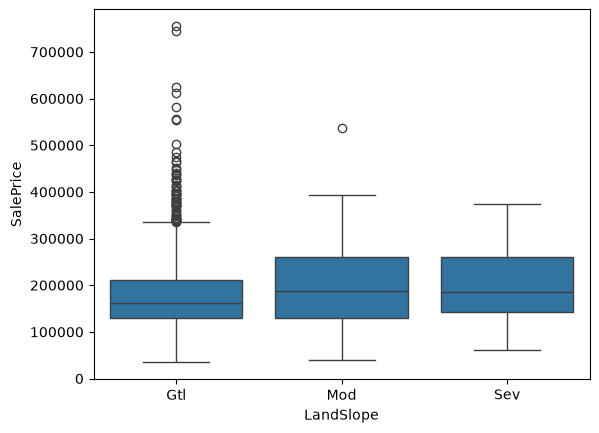

In [347]:
sns.boxplot(
    data=df,
    x=df['LandSlope'],
    y=df['SalePrice']
)

plt.show()

Neighbourhood

In [348]:
df['Neighborhood'].value_counts()

Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
StoneBr     25
SWISU       25
MeadowV     17
Blmngtn     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

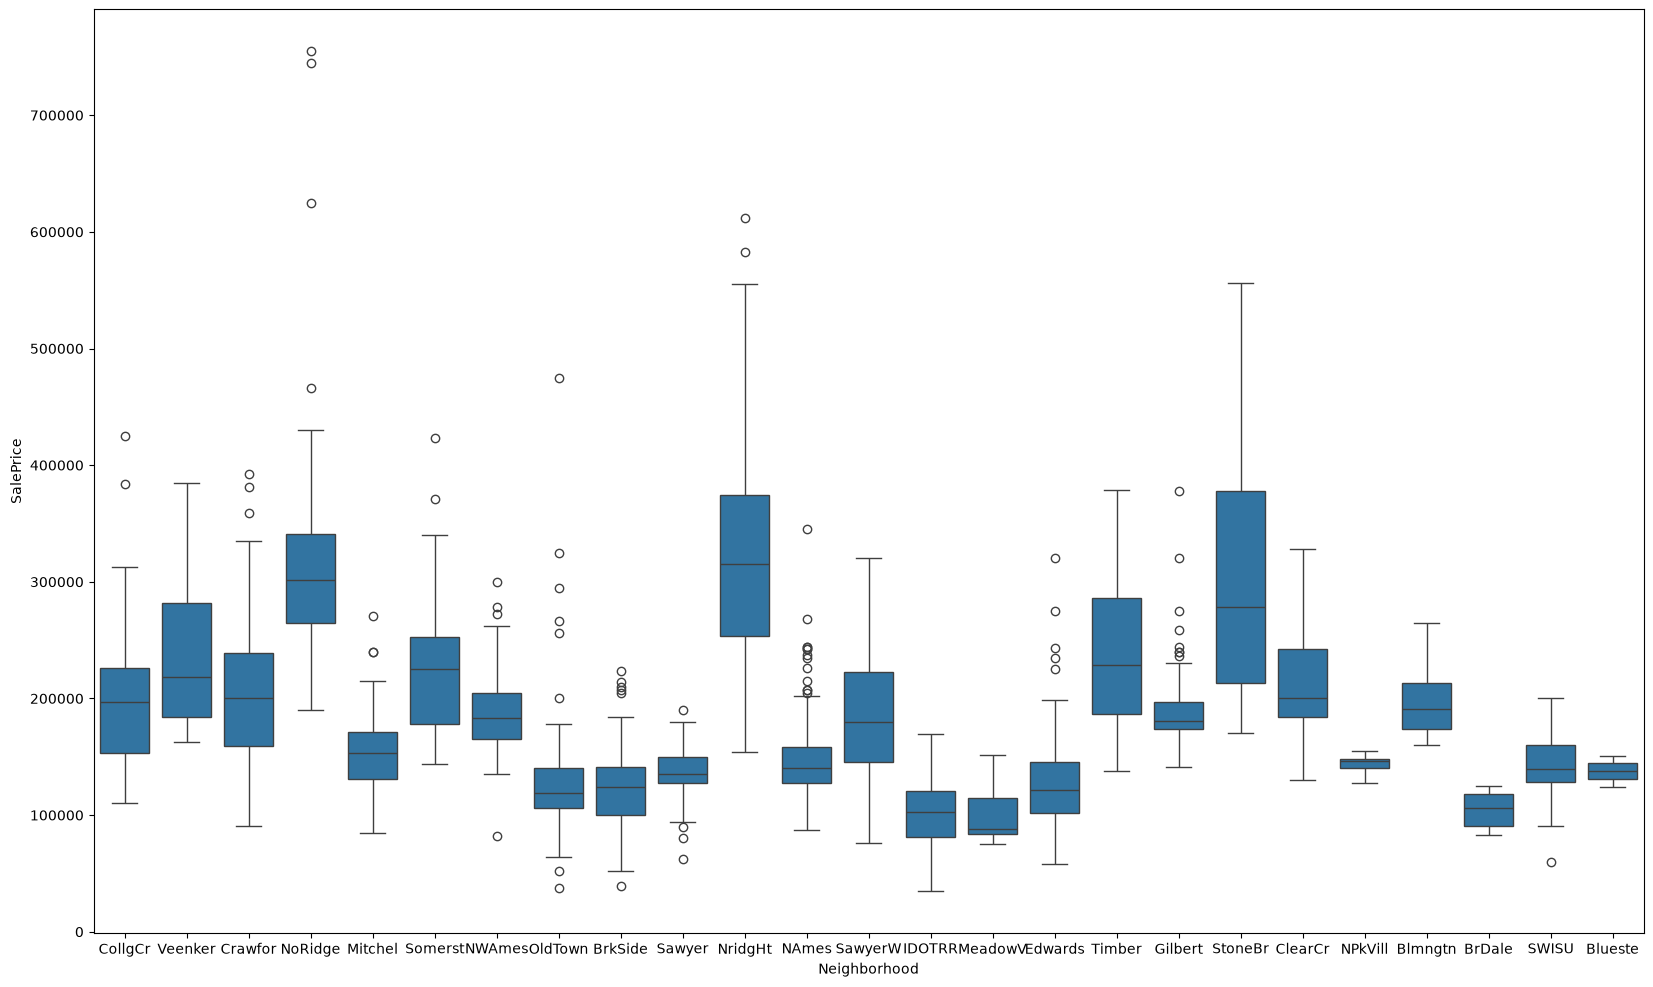

In [349]:
plt.figure(figsize=(20,12))
sns.boxplot(
    data=df,
    x='Neighborhood',
    y='SalePrice'
)
plt.tight_layout
plt.show()

Condition 1&2

In [350]:
df['Condition1'].value_counts()

Condition1
Norm      1260
Feedr       81
Artery      48
RRAn        26
PosN        19
RRAe        11
PosA         8
RRNn         5
RRNe         2
Name: count, dtype: int64

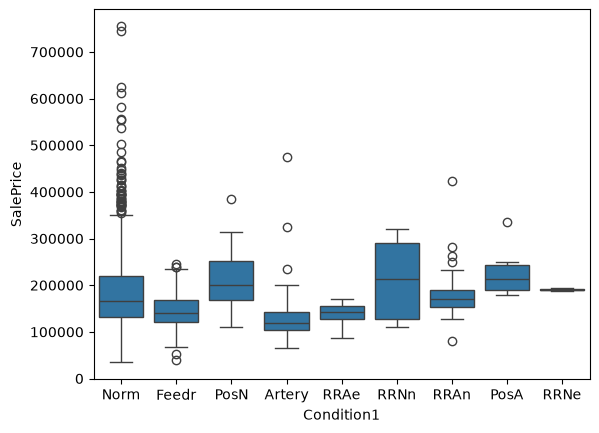

In [351]:
sns.boxplot(
    data=df,
    x=df['Condition1'],
    y=df['SalePrice']
)

plt.show()

In [352]:
df['Condition2'].value_counts()

Condition2
Norm      1445
Feedr        6
Artery       2
RRNn         2
PosN         2
PosA         1
RRAn         1
RRAe         1
Name: count, dtype: int64

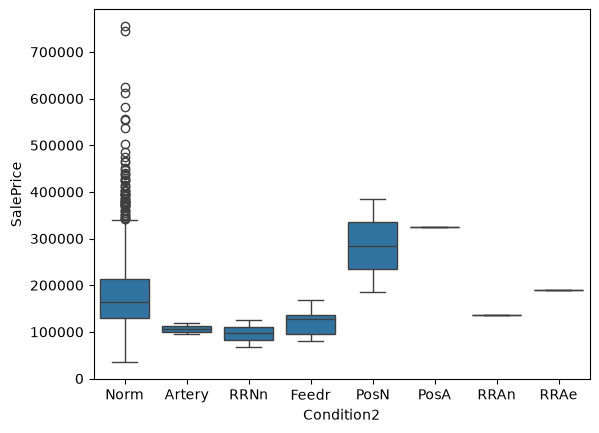

In [353]:
sns.boxplot(
    data=df,
    x=df['Condition2'],
    y=df['SalePrice']
)

plt.show()

BldgType

In [354]:
df['BldgType'].value_counts()

BldgType
1Fam      1220
TwnhsE     114
Duplex      52
Twnhs       43
2fmCon      31
Name: count, dtype: int64

HouseStyle

In [355]:
df['HouseStyle'].value_counts()

HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64

OverallQual

In [356]:
df['OverallQual'].value_counts()

OverallQual
5     397
6     374
7     319
8     168
4     116
9      43
3      20
10     18
2       3
1       2
Name: count, dtype: int64

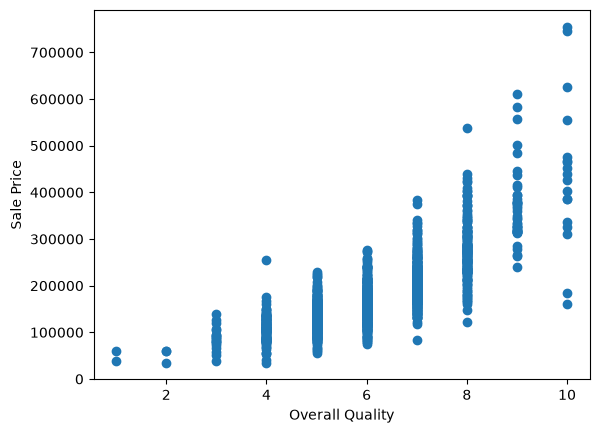

In [357]:
plt.scatter(df['OverallQual'],df['SalePrice'])
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price')
plt.show()

OverallCond

In [358]:
df['OverallCond'].value_counts()

OverallCond
5    821
6    252
7    205
8     72
4     57
3     25
9     22
2      5
1      1
Name: count, dtype: int64

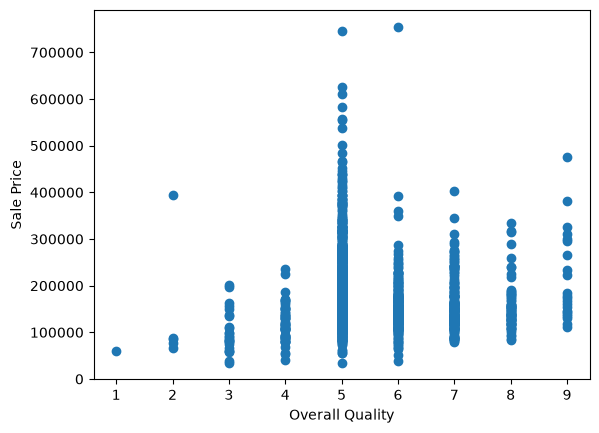

In [359]:
plt.scatter(df['OverallCond'],df['SalePrice'])
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price')
plt.show()

<Axes: xlabel='OverallCond', ylabel='SalePrice'>

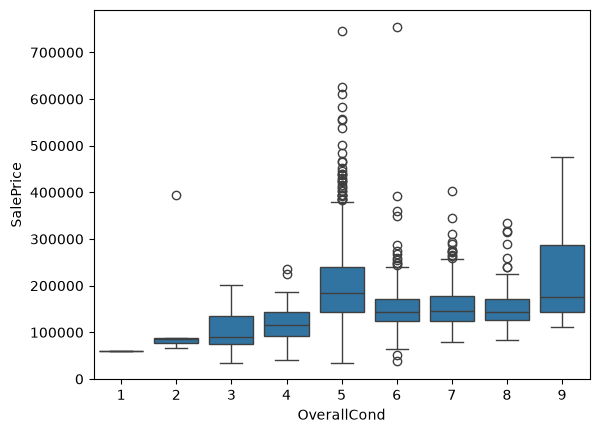

In [360]:
sns.boxplot(
    data=df,
    x='OverallCond',
    y='SalePrice'
)

YearBuilt

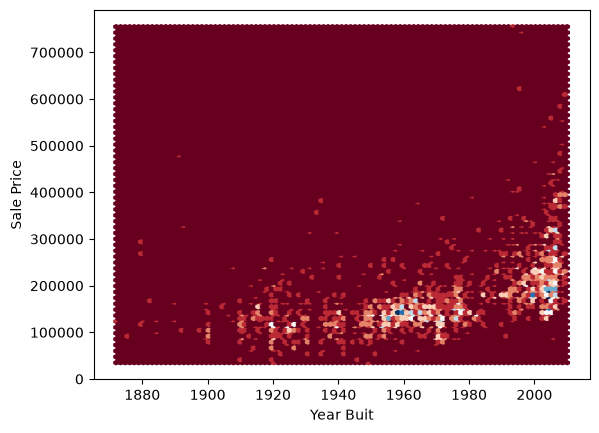

In [361]:
plt.hexbin(x=df['YearBuilt'],y=df['SalePrice'],cmap='RdBu')
plt.xlabel('Year Buit')
plt.ylabel('Sale Price')
plt.show()

YearRemodAdd

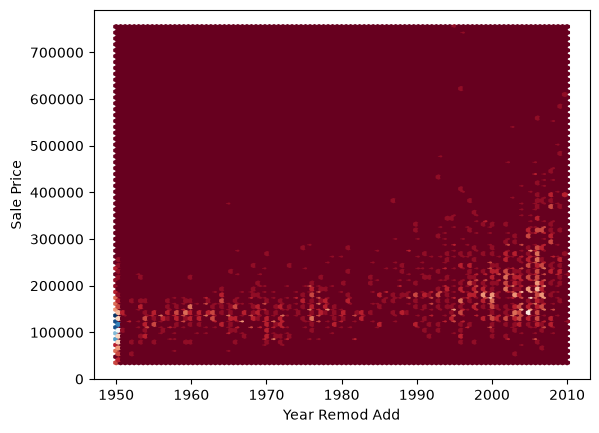

In [362]:
plt.hexbin(x=df['YearRemodAdd'],y=df['SalePrice'],cmap='RdBu')
plt.xlabel('Year Remod Add')
plt.ylabel('Sale Price')
plt.show()

RoofStyle

In [363]:
df['RoofStyle'].value_counts()

RoofStyle
Gable      1141
Hip         286
Flat         13
Gambrel      11
Mansard       7
Shed          2
Name: count, dtype: int64

RoofMatl

In [364]:
df['RoofMatl'].value_counts()

RoofMatl
CompShg    1434
Tar&Grv      11
WdShngl       6
WdShake       5
Metal         1
Membran       1
Roll          1
ClyTile       1
Name: count, dtype: int64

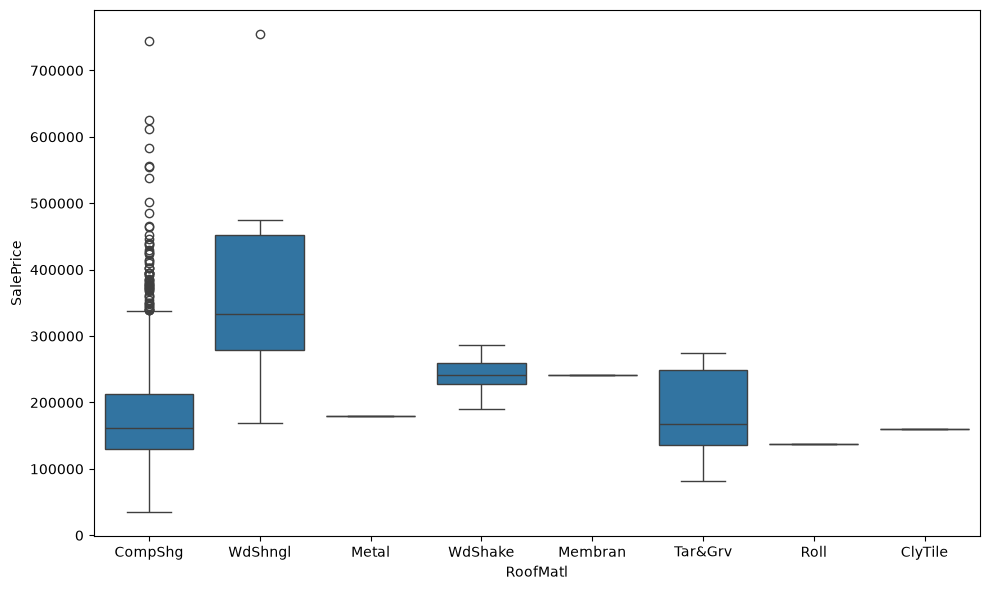

In [365]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df,
    x='RoofMatl',
    y='SalePrice'
)
plt.tight_layout()
plt.show()

Exterior1st & Exterior2nd

In [366]:
df['Exterior1st'].value_counts()

Exterior1st
VinylSd    515
HdBoard    222
MetalSd    220
Wd Sdng    206
Plywood    108
CemntBd     61
BrkFace     50
WdShing     26
Stucco      25
AsbShng     20
BrkComm      2
Stone        2
AsphShn      1
ImStucc      1
CBlock       1
Name: count, dtype: int64

In [367]:
df['Exterior2nd'].value_counts()

Exterior2nd
VinylSd    504
MetalSd    214
HdBoard    207
Wd Sdng    197
Plywood    142
CmentBd     60
Wd Shng     38
Stucco      26
BrkFace     25
AsbShng     20
ImStucc     10
Brk Cmn      7
Stone        5
AsphShn      3
Other        1
CBlock       1
Name: count, dtype: int64

<Axes: ylabel='Exterior1st'>

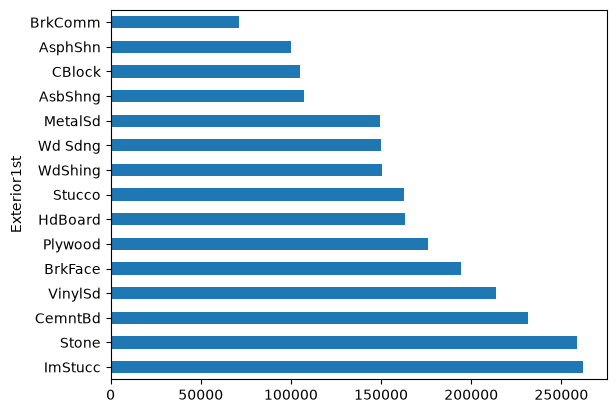

In [368]:
df.groupby('Exterior1st')['SalePrice'].mean().sort_values(ascending=False).plot(kind='barh')

<Axes: ylabel='Exterior2nd'>

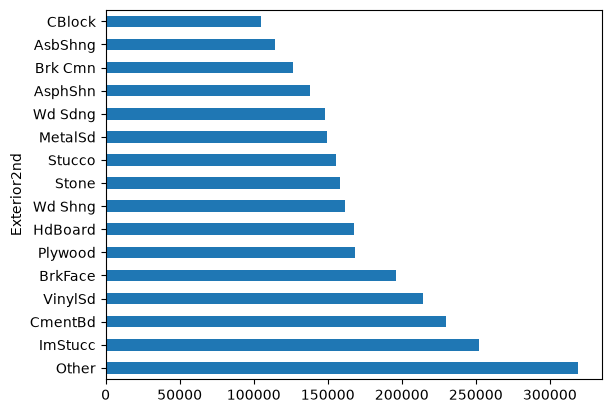

In [369]:
df.groupby('Exterior2nd')['SalePrice'].mean().sort_values(ascending=False).plot(kind='barh')

MasVnrType

In [370]:
df['MasVnrType'].isnull().sum()

np.int64(872)

In [371]:
df['MasVnrType'].value_counts()

MasVnrType
BrkFace    445
Stone      128
BrkCmn      15
Name: count, dtype: int64

In [372]:
df['MasVnrType']=df['MasVnrType'].fillna('None')
df['MasVnrType'].value_counts()

MasVnrType
None       872
BrkFace    445
Stone      128
BrkCmn      15
Name: count, dtype: int64

MasVnrArea

In [373]:
df['MasVnrArea'].isnull().sum()

np.int64(8)

In [374]:
df['MasVnrArea'] = df['MasVnrArea'].fillna(0)

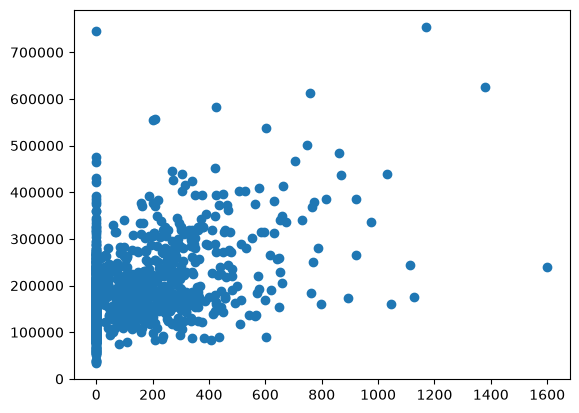

In [375]:
plt.scatter(x=df['MasVnrArea'],y=df['SalePrice'])

ExterQual

In [376]:
df['ExterQual'].value_counts()

ExterQual
TA    906
Gd    488
Ex     52
Fa     14
Name: count, dtype: int64

<Axes: ylabel='ExterQual'>

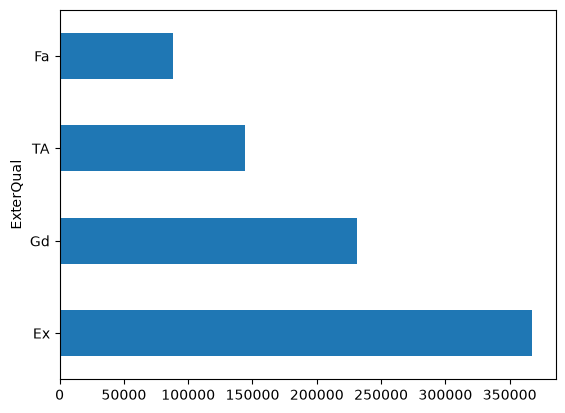

In [377]:
df.groupby('ExterQual')['SalePrice'].mean().sort_values(ascending=False).plot(kind='barh')

In [378]:
df['ExterQual'] = df['ExterQual'].map({
    'Ex' : 4,
    'Gd' : 3,
    'TA' : 2,
    'Fa' : 1
})

In [379]:
df['ExterQual'].value_counts()

ExterQual
2    906
3    488
4     52
1     14
Name: count, dtype: int64

ExterCond

In [380]:
df['ExterCond'].value_counts()

ExterCond
TA    1282
Gd     146
Fa      28
Ex       3
Po       1
Name: count, dtype: int64

<Axes: ylabel='ExterCond'>

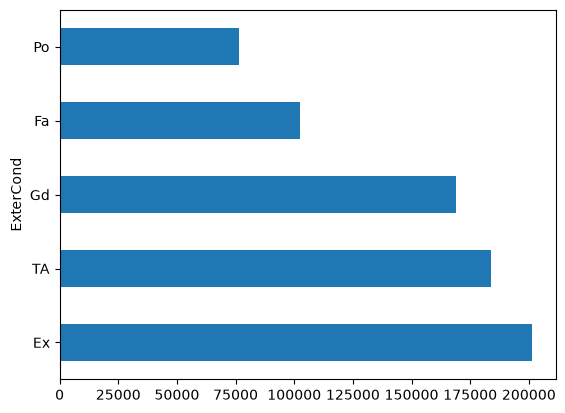

In [381]:
df.groupby('ExterCond')['SalePrice'].mean().sort_values(ascending=False).plot(kind='barh')

In [382]:
df['ExterCond'] = df['ExterCond'].map({
    'Ex' : 5,
    'Gd' : 4,
    'TA' : 3,
    'Fa' : 2,
    'Po' : 1
})

Foundation

In [383]:
df['Foundation'].value_counts()

Foundation
PConc     647
CBlock    634
BrkTil    146
Slab       24
Stone       6
Wood        3
Name: count, dtype: int64

<Axes: xlabel='Foundation', ylabel='SalePrice'>

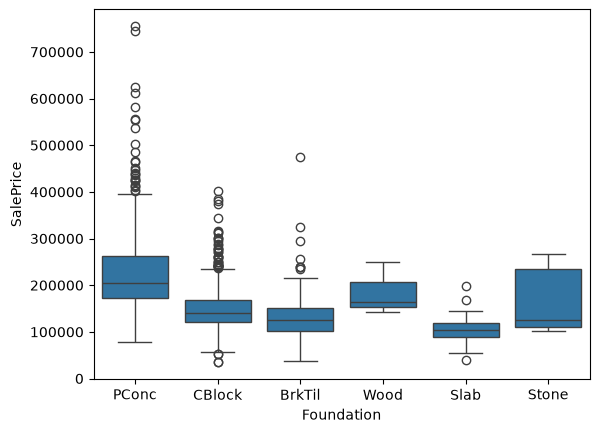

In [384]:
sns.boxplot(x=df['Foundation'],y=df['SalePrice'])

BsmtQual

In [385]:
df['BsmtQual'].value_counts()

BsmtQual
TA    649
Gd    618
Ex    121
Fa     35
Name: count, dtype: int64

In [386]:
df['BsmtQual'].isna().sum()

np.int64(37)

In [387]:
df['BsmtQual'] = df['BsmtQual'].fillna("None")

In [388]:
df['BsmtQual'] = df['BsmtQual'].map({
    'Ex' : 4,
    'Gd' : 3,
    'TA' : 2,
    'Fa' : 1,
    "None" : 0
})

BsmtCond

In [389]:
df['BsmtCond'].value_counts()

BsmtCond
TA    1311
Gd      65
Fa      45
Po       2
Name: count, dtype: int64

In [390]:
df['BsmtCond'].isna().sum()

np.int64(37)

In [391]:
df['BsmtCond'] = df['BsmtCond'].fillna("None")

In [392]:
df['BsmtCond'] = df['BsmtCond'].map({
    'Gd' : 4,
    'TA' : 3,
    'Fa' : 2,
    'Po' : 1,
    "None" : 0
})

In [393]:
df['BsmtCond'].value_counts()

BsmtCond
3    1311
4      65
2      45
0      37
1       2
Name: count, dtype: int64

BsmtExposure

In [394]:
df['BsmtExposure'].value_counts()

BsmtExposure
No    953
Av    221
Gd    134
Mn    114
Name: count, dtype: int64

In [395]:
df['BsmtExposure'].isna().sum()

np.int64(38)

In [396]:
df['BsmtExposure'] = df['BsmtExposure'].fillna("No") # missing values mean they also have no exposure like 'No' class...so we add them with this one and turn them to 0 collectively next

In [397]:
df['BsmtExposure'] = df['BsmtExposure'].map({
    'No': 0,
    'Mn': 1,
    'Av': 2,
    'Gd': 3
})

BsmtFinType1

In [398]:
df['BsmtFinType1'].value_counts()

BsmtFinType1
Unf    430
GLQ    418
ALQ    220
BLQ    148
Rec    133
LwQ     74
Name: count, dtype: int64

In [399]:
df['BsmtFinType1'] = df['BsmtFinType1'].fillna('None')

In [400]:

df['BsmtFinType1'] = df['BsmtFinType1'].map({
    'None': 0,
    'Unf': 1,
    'LwQ': 2,
    'Rec': 3,
    'BLQ': 4,
    'ALQ': 5,
    'GLQ': 6
})

BsmtFinSF1

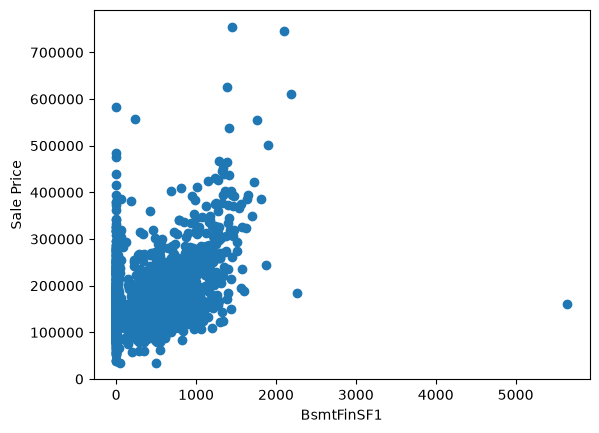

In [401]:
plt.scatter(x=df['BsmtFinSF1'],y=df['SalePrice'])
plt.xlabel("BsmtFinSF1")
plt.ylabel("Sale Price")
plt.show()

BsmtFinType2

In [402]:
df['BsmtFinType2'].value_counts()

BsmtFinType2
Unf    1256
Rec      54
LwQ      46
BLQ      33
ALQ      19
GLQ      14
Name: count, dtype: int64

In [403]:
df['BsmtFinType2'] = df['BsmtFinType2'].fillna('None')

In [404]:

df['BsmtFinType2'] = df['BsmtFinType2'].map({
    'None': 0,
    'Unf': 1,
    'LwQ': 2,
    'Rec': 3,
    'BLQ': 4,
    'ALQ': 5,
    'GLQ': 6
})

BsmtFinSF2

In [405]:
df['BsmtFinSF2'].describe()

count    1460.000000
mean       46.549315
std       161.319273
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max      1474.000000
Name: BsmtFinSF2, dtype: float64

In [406]:
(df['BsmtFinSF2']==0).sum()

np.int64(1293)

<Axes: xlabel='BsmtFinSF2', ylabel='SalePrice'>

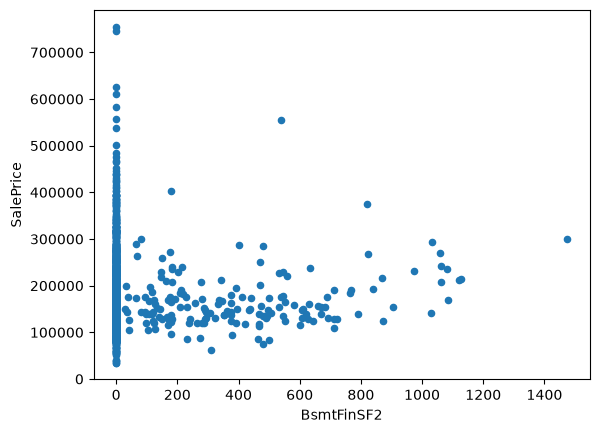

In [407]:
df.plot(x='BsmtFinSF2',y='SalePrice',kind='scatter')

BsmtUnfSF

<Axes: xlabel='BsmtUnfSF', ylabel='SalePrice'>

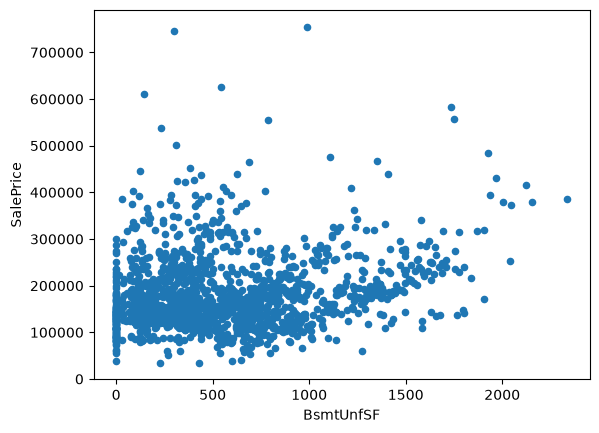

In [408]:
df.plot(x='BsmtUnfSF',y='SalePrice',kind='scatter')

TotalBsmtSF

<Axes: xlabel='TotalBsmtSF', ylabel='SalePrice'>

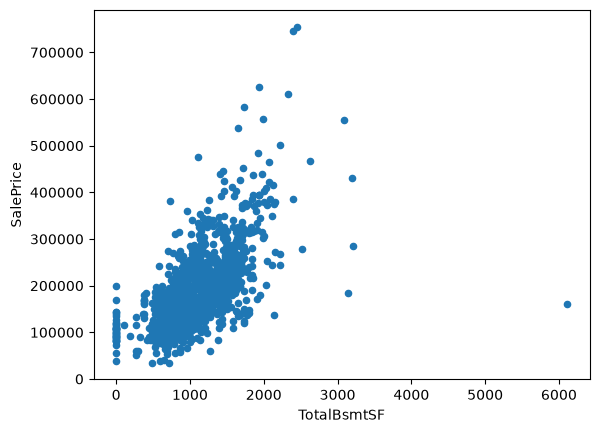

In [409]:
df.plot(x='TotalBsmtSF',y='SalePrice',kind='scatter')

Heating

In [410]:
df['Heating'].value_counts()

Heating
GasA     1428
GasW       18
Grav        7
Wall        4
OthW        2
Floor       1
Name: count, dtype: int64

HeatingQC

In [411]:
df['HeatingQC'].value_counts()

HeatingQC
Ex    741
TA    428
Gd    241
Fa     49
Po      1
Name: count, dtype: int64

In [412]:
df['HeatingQC'] = df['HeatingQC'].map({
    'Po' : 1,
    'Fa' : 2,
    'TA' : 3,
    'Gd' : 4,
    'Ex' : 5
})

CentralAir

In [413]:
df['CentralAir'].value_counts()

CentralAir
Y    1365
N      95
Name: count, dtype: int64

In [414]:
df['CentralAir'] = df['CentralAir'].map({
    'N': 0,
    'Y': 1
})

Electrical

In [415]:
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

In [416]:
df['Electrical'].value_counts()

Electrical
SBrkr    1335
FuseA      94
FuseF      27
FuseP       3
Mix         1
Name: count, dtype: int64

1stFlrSF

<Axes: xlabel='1stFlrSF', ylabel='SalePrice'>

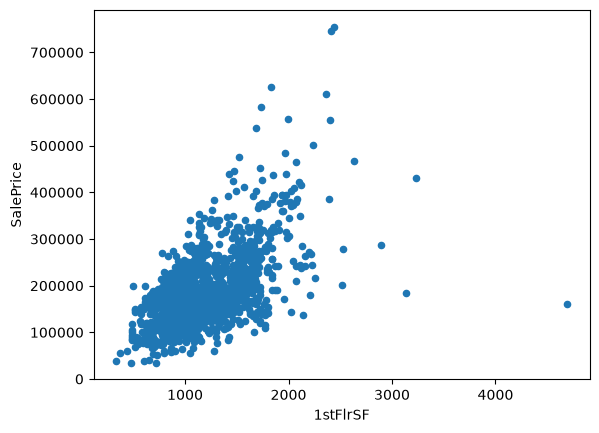

In [417]:
df.plot(x='1stFlrSF',y='SalePrice',kind='scatter')

2ndFlrSF

<Axes: xlabel='2ndFlrSF', ylabel='SalePrice'>

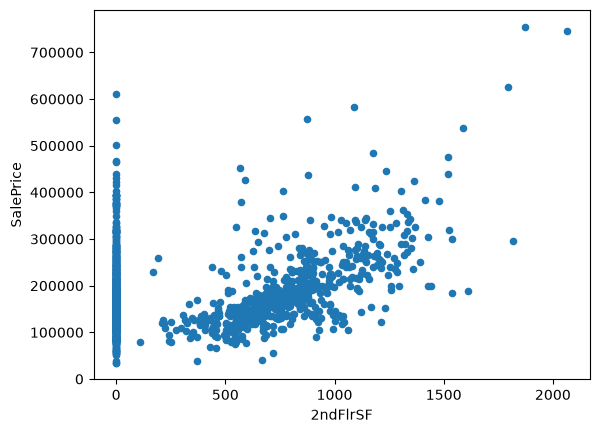

In [418]:
df.plot(x='2ndFlrSF',y='SalePrice',kind='scatter')

LowQualFinSF

In [419]:
(df['LowQualFinSF']==0).sum()

np.int64(1434)

<Axes: xlabel='LowQualFinSF', ylabel='SalePrice'>

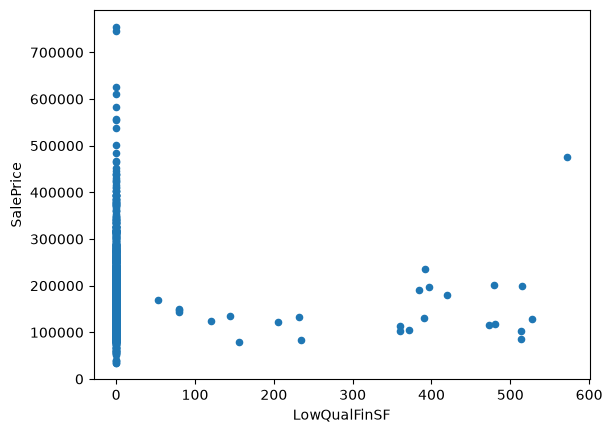

In [420]:
df.plot(x='LowQualFinSF',y='SalePrice',kind='scatter')

GrLivArea

<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

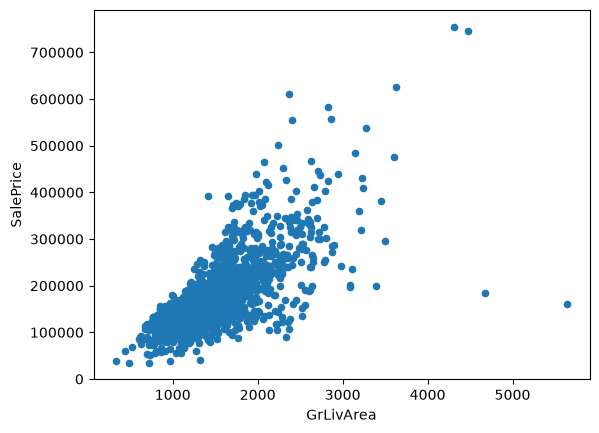

In [421]:
df.plot(x='GrLivArea',y='SalePrice',kind='scatter')

BsmtFullBath

In [422]:
df['BsmtFullBath'].value_counts()

BsmtFullBath
0    856
1    588
2     15
3      1
Name: count, dtype: int64

BsmtHalfBath

In [423]:
df['BsmtHalfBath'].value_counts()

BsmtHalfBath
0    1378
1      80
2       2
Name: count, dtype: int64

FullBath

In [424]:
df['FullBath'].value_counts()

FullBath
2    768
1    650
3     33
0      9
Name: count, dtype: int64

HalfBath

In [425]:
df['HalfBath'].value_counts()

HalfBath
0    913
1    535
2     12
Name: count, dtype: int64

BedroomAbvGr

In [426]:
df['BedroomAbvGr'].value_counts()

BedroomAbvGr
3    804
2    358
4    213
1     50
5     21
6      7
0      6
8      1
Name: count, dtype: int64

KitchenAbvGr

In [427]:
df['KitchenAbvGr'].value_counts()

KitchenAbvGr
1    1392
2      65
3       2
0       1
Name: count, dtype: int64

KitchenQual

In [428]:
df['KitchenQual'].value_counts()

KitchenQual
TA    735
Gd    586
Ex    100
Fa     39
Name: count, dtype: int64

In [429]:
df['KitchenQual'] = df['KitchenQual'].map({
    'Fa' : 1,
    'TA' : 2,
    'Gd' : 3,
    'Ex' : 4
})

TotRmsAbvGrd

In [430]:
df['TotRmsAbvGrd'].value_counts()

TotRmsAbvGrd
6     402
7     329
5     275
8     187
4      97
9      75
10     47
11     18
3      17
12     11
2       1
14      1
Name: count, dtype: int64

<Axes: xlabel='TotRmsAbvGrd', ylabel='SalePrice'>

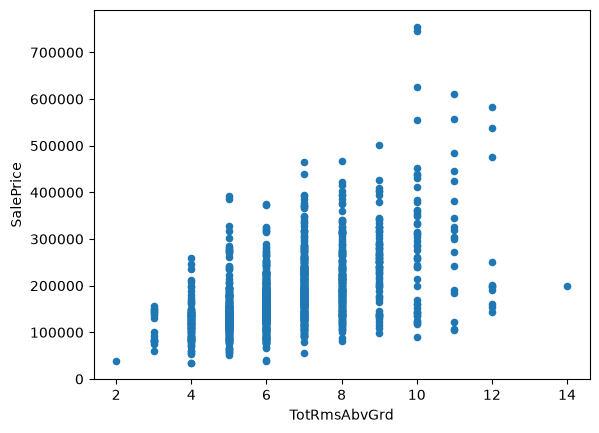

In [431]:
df.plot(x='TotRmsAbvGrd',y='SalePrice',kind='scatter')

Functional

In [432]:
df['Functional'].value_counts()

Functional
Typ     1360
Min2      34
Min1      31
Mod       15
Maj1      14
Maj2       5
Sev        1
Name: count, dtype: int64

Fireplaces

In [433]:
df['Fireplaces'].value_counts()

Fireplaces
0    690
1    650
2    115
3      5
Name: count, dtype: int64

FireplaceQu

In [434]:
df['FireplaceQu'].isnull().sum()

np.int64(690)

In [435]:
df['FireplaceQu'] = df['FireplaceQu'].fillna('None')

In [436]:
df['FireplaceQu'].value_counts()

FireplaceQu
None    690
Gd      380
TA      313
Fa       33
Ex       24
Po       20
Name: count, dtype: int64

In [437]:
df['FireplaceQu'] = df['FireplaceQu'].map({
    'None' : 0,
    'Po' : 1,
    'Fa' : 2,
    'TA' : 3,
    'Gd' : 4,
    'Ex' : 5
})

GarageType

In [438]:
df['GarageType'].isnull().sum()

np.int64(81)

In [439]:
df['GarageType'] = df['GarageType'].fillna('None')

In [440]:
df['GarageType'].value_counts()

GarageType
Attchd     870
Detchd     387
BuiltIn     88
None        81
Basment     19
CarPort      9
2Types       6
Name: count, dtype: int64

GarageYrBlt

In [441]:
df['GarageYrBlt'].isnull().sum()

np.int64(81)

<Axes: xlabel='GarageYrBlt', ylabel='SalePrice'>

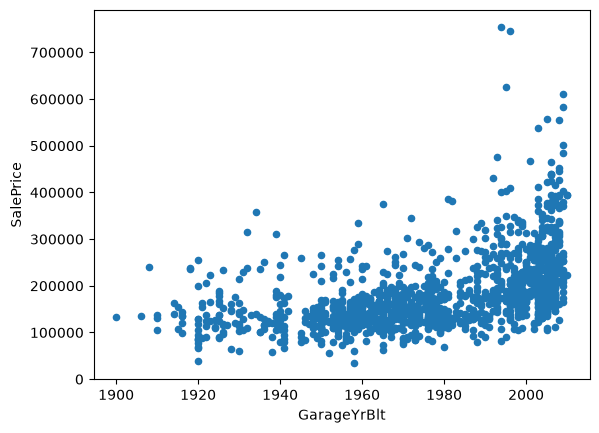

In [442]:
df.plot(x='GarageYrBlt',y='SalePrice',kind='scatter')

GarageFinish

In [443]:
df['GarageFinish'].value_counts()

GarageFinish
Unf    605
RFn    422
Fin    352
Name: count, dtype: int64

In [444]:
df['GarageFinish'].isnull().sum()

np.int64(81)

In [445]:
df['GarageFinish']=df['GarageFinish'].fillna('None')

In [446]:
df['GarageFinish'] = df['GarageFinish'].map({
    'None': 0,
    'Unf' : 1,
    'RFn' : 2,
    'Fin' : 3
})

GarageCars

In [447]:
df['GarageCars'].value_counts()

GarageCars
2    824
1    369
3    181
0     81
4      5
Name: count, dtype: int64

<Axes: xlabel='GarageCars', ylabel='SalePrice'>

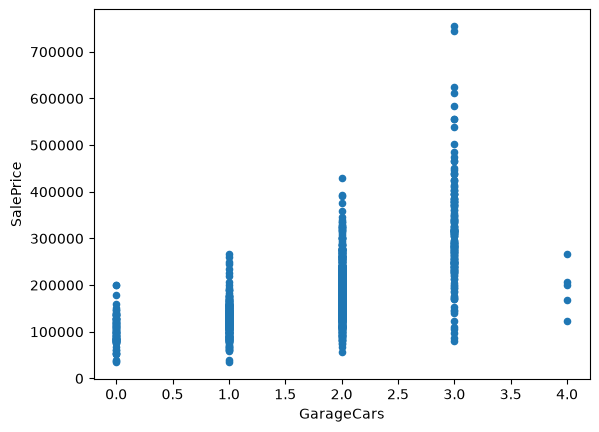

In [448]:
df.plot(x='GarageCars',y='SalePrice',kind='scatter')

GarageArea

<Axes: xlabel='GarageArea', ylabel='SalePrice'>

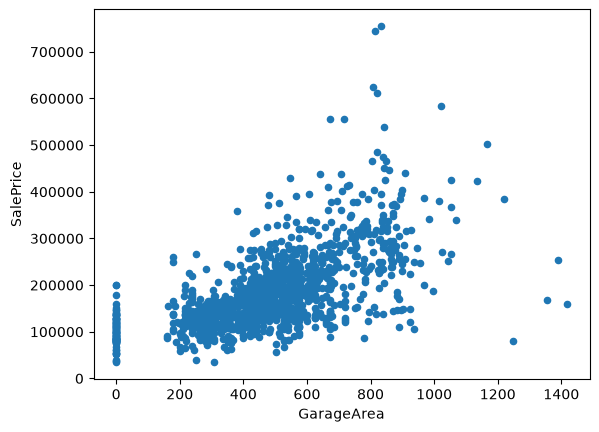

In [449]:
df.plot(x='GarageArea',y='SalePrice',kind='scatter')

GarageQual

In [450]:
df['GarageQual'].isnull().sum()

np.int64(81)

In [451]:
df['GarageQual'] = df['GarageQual'].fillna('None')

In [452]:
df['GarageQual'].value_counts()

GarageQual
TA      1311
None      81
Fa        48
Gd        14
Ex         3
Po         3
Name: count, dtype: int64

In [453]:
df['GarageQual'] = df['GarageQual'].map({
    'None' : 0,
    'Po' : 1,
    'Fa' : 2,
    'TA' : 3,
    'Gd' : 4,
    'Ex' : 5
})

GarageCond

In [454]:
df['GarageCond'].isnull().sum()

np.int64(81)

In [455]:
df['GarageCond'] = df['GarageCond'].fillna('None')

In [456]:
df['GarageCond'].value_counts()

GarageCond
TA      1326
None      81
Fa        35
Gd         9
Po         7
Ex         2
Name: count, dtype: int64

In [457]:
df['GarageCond'] = df['GarageCond'].map({
    'None' : 0,
    'Po' : 1,
    'Fa' : 2,
    'TA' : 3,
    'Gd' : 4,
    'Ex' : 5
})

PavedDrive

In [458]:
df['PavedDrive'].value_counts()

PavedDrive
Y    1340
N      90
P      30
Name: count, dtype: int64

In [459]:
df['PavedDrive'] = df['PavedDrive'].map({
    'N': 0,
    'P': 1,
    'Y': 2
})

WoodDeckSF

In [460]:
df['WoodDeckSF'].describe()

count    1460.000000
mean       94.244521
std       125.338794
min         0.000000
25%         0.000000
50%         0.000000
75%       168.000000
max       857.000000
Name: WoodDeckSF, dtype: float64

<Axes: xlabel='WoodDeckSF', ylabel='SalePrice'>

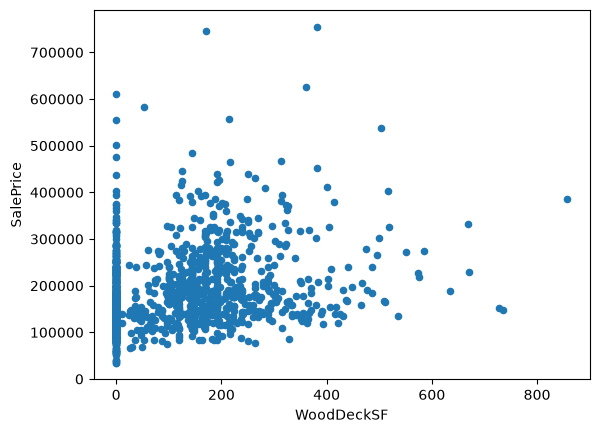

In [461]:
df.plot(x='WoodDeckSF',y='SalePrice',kind='scatter')

OpenPorchSF

<Axes: xlabel='OpenPorchSF', ylabel='SalePrice'>

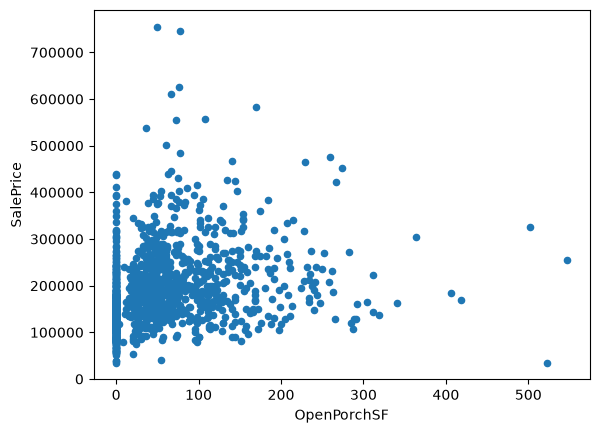

In [462]:
df.plot(x='OpenPorchSF',y='SalePrice',kind='scatter')

EnclosedPorch

In [463]:
(df['EnclosedPorch']==0).sum()

np.int64(1252)

<Axes: xlabel='EnclosedPorch', ylabel='SalePrice'>

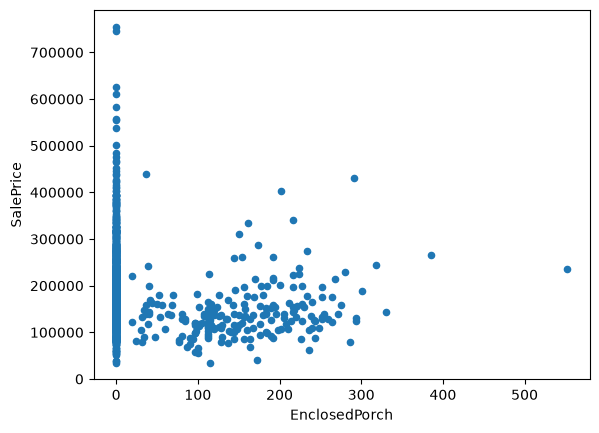

In [464]:
df.plot(x='EnclosedPorch',y='SalePrice',kind='scatter')

3SsnPorch

In [465]:
df['3SsnPorch'].isnull().sum()

np.int64(0)

In [466]:
(df['3SsnPorch']==0).sum()

np.int64(1436)

<Axes: xlabel='3SsnPorch', ylabel='SalePrice'>

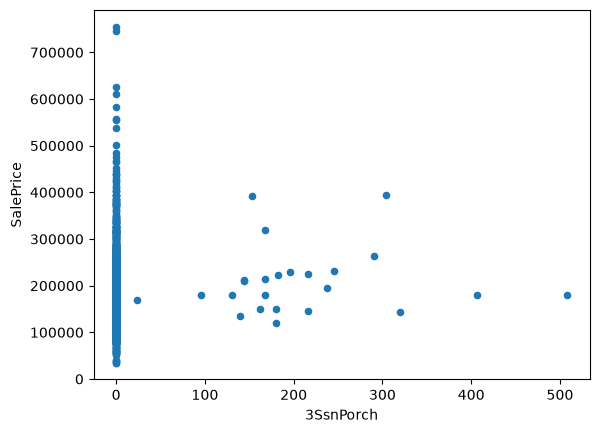

In [467]:
df.plot(x='3SsnPorch',y='SalePrice',kind='scatter')

ScreenPorch

In [468]:
(df['ScreenPorch']==0).sum()

np.int64(1344)

In [469]:
df['ScreenPorch'].isnull().sum()

np.int64(0)

<Axes: xlabel='ScreenPorch', ylabel='SalePrice'>

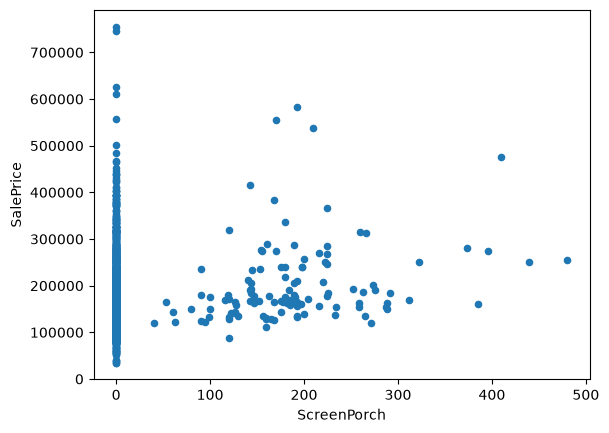

In [470]:
df.plot(x='ScreenPorch',y='SalePrice',kind='scatter')

PoolArea

In [471]:
(df['PoolArea']==0).sum()

np.int64(1453)

In [472]:
df['PoolArea'].isnull().sum()

np.int64(0)

<Axes: xlabel='PoolArea', ylabel='SalePrice'>

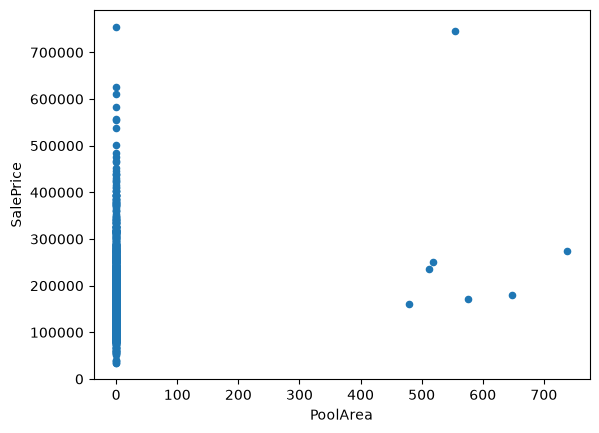

In [473]:
df.plot(x='PoolArea',y='SalePrice',kind='scatter')

PoolQC

In [474]:
df['PoolQC'].isnull().sum()

np.int64(1453)

In [475]:
df['PoolQC'].value_counts()

PoolQC
Gd    3
Ex    2
Fa    2
Name: count, dtype: int64

In [476]:
df['PoolQC']=df['PoolQC'].fillna('None')

In [477]:
df['PoolQC']=df['PoolQC'].map({
    'None' : 0,
    'Fa'   : 1,
    'Gd'   : 2,
    'Ex'   : 3
})

Fence

In [478]:
df['Fence'].value_counts()

Fence
MnPrv    157
GdPrv     59
GdWo      54
MnWw      11
Name: count, dtype: int64

In [479]:
df['Fence'].isnull().sum()

np.int64(1179)

In [480]:
df['Fence']=df['Fence'].fillna('None')

MiscFeature

In [481]:
df['MiscFeature'].value_counts()

MiscFeature
Shed    49
Gar2     2
Othr     2
TenC     1
Name: count, dtype: int64

In [482]:
df['MiscFeature'].isnull().sum()

np.int64(1406)

In [483]:
df['MiscFeature'] = df['MiscFeature'].fillna('None')

MiscVal

In [484]:
df['MiscVal'].value_counts()[0]

np.int64(1408)

<Axes: xlabel='MiscVal', ylabel='SalePrice'>

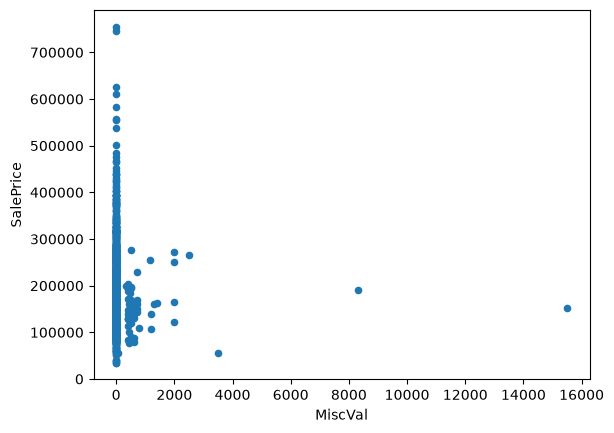

In [485]:
df.plot(x='MiscVal',y='SalePrice',kind='scatter')

MoSold

<Axes: xlabel='MoSold', ylabel='SalePrice'>

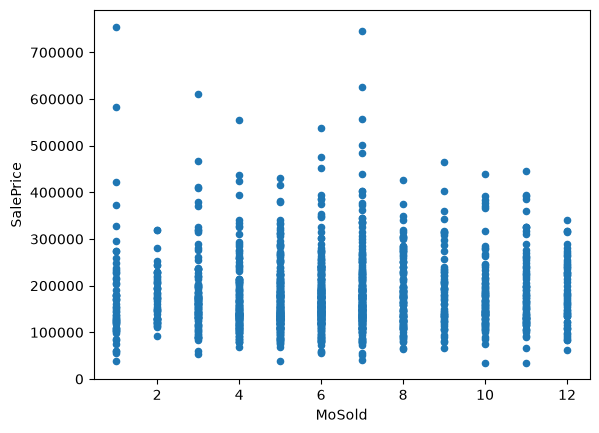

In [486]:
df.plot(x='MoSold',y='SalePrice',kind='scatter')

YrSold

<Axes: xlabel='YrSold', ylabel='SalePrice'>

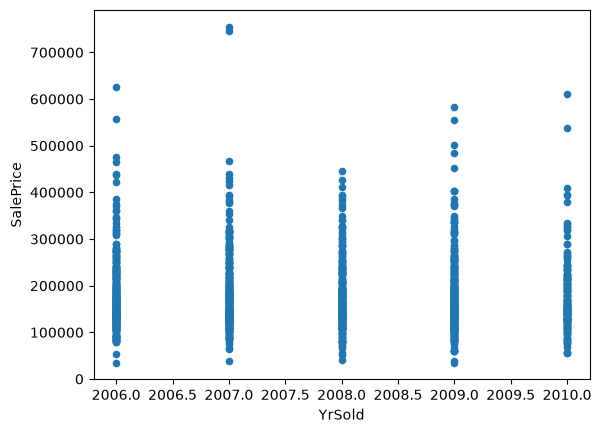

In [487]:
df.plot(x='YrSold',y='SalePrice',kind='scatter')

SaleType

In [488]:
df['SaleType'].value_counts()

SaleType
WD       1267
New       122
COD        43
ConLD       9
ConLI       5
ConLw       5
CWD         4
Oth         3
Con         2
Name: count, dtype: int64

SaleCondition

In [489]:
df['SaleCondition'].value_counts()

SaleCondition
Normal     1198
Partial     125
Abnorml     101
Family       20
Alloca       12
AdjLand       4
Name: count, dtype: int64

end of EDA (we actually did some ordinal encoding simultaneously though it should've be done later)

In [490]:
df.shape

(1460, 81)

In [491]:
df.isnull().sum().sort_values(ascending=False).head(10)

GarageYrBlt    81
MSSubClass      0
MSZoning        0
LotFrontage     0
LotArea         0
Street          0
Alley           0
LotShape        0
LandContour     0
Utilities       0
dtype: int64

we see 7 colums with missing values....now we analyse and fill them

In [492]:
df['GarageYrBlt'].isnull().sum()

np.int64(81)

In [493]:
df['GarageAge']=df['YrSold']-df['GarageYrBlt']

In [494]:
df['GarageAge'].head(20)

0      5.0
1     31.0
2      7.0
3      8.0
4      8.0
5     16.0
6      3.0
7     36.0
8     77.0
9     69.0
10    43.0
11     1.0
12    46.0
13     1.0
14    48.0
15    16.0
16    40.0
17    39.0
18     4.0
19    51.0
Name: GarageAge, dtype: float64

In [495]:
df.loc[df['GarageYrBlt'].isna(),'GarageAge'] = 0

In [496]:
df['GarageAge'].isnull().sum()

np.int64(0)

In [497]:
df = df.drop('GarageYrBlt',axis=1)

moving forward to One Hot Encoding

In [498]:
# we just checked which columns still have objects in their values instead of numbers
categorical_col = df.select_dtypes(include='object').columns.tolist()
print(categorical_col)

['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'Electrical', 'Functional', 'GarageType', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


C:\Users\Laptop King\AppData\Local\Temp\ipykernel_17260\4141647871.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_col = df.select_dtypes(include='object').columns.tolist()


In [499]:
print('number of column categories:',len(categorical_col))

number of column categories: 27


In [500]:
df = df.drop(['Id'],axis=1)

In [501]:
problematic = ['Street','Utilities','Condition2','RoofMatl','BsmtFinSF2','Heating','LowQualFinSF','EnclosedPorch','3SsnPorch','ScreenPorch','PoolArea','MoSold']

In [502]:
OHE_material = ['MSSubClass','MSZoning','Alley','LotShape','LandContour','LotConfig','LandSlope','Neighborhood','Condition1','BldgType','HouseStyle','RoofStyle','Exterior1st',
                'Exterior2nd','MasVnrType','Foundation','Electrical','Functional','GarageType','Fence','MiscFeature','SaleType','SaleCondition']

In [503]:
for var in OHE_material:
    df = pd.get_dummies(df,columns=[var],dtype=int)

In [504]:
problematic_OHE_candidates = df.select_dtypes(include='object').columns.tolist()
print(problematic_OHE_candidates)

['Street', 'Utilities', 'Condition2', 'RoofMatl', 'Heating']


C:\Users\Laptop King\AppData\Local\Temp\ipykernel_17260\1883097080.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  problematic_OHE_candidates = df.select_dtypes(include='object').columns.tolist()


In [505]:
# these above four are also OHE candidates but they are in the problematic categories....so for now we will OHE them for that further model evaluation
for var in problematic_OHE_candidates:
    df = pd.get_dummies(df,columns=[var],dtype=int)

for every column of problematic list.....we will later build 2 different models with and without it and compare the prediction to decide whether to drop or keep

In [506]:
df.isnull().sum().sort_values(ascending=False).head(10)

LotFrontage     0
LotArea         0
OverallQual     0
OverallCond     0
YearBuilt       0
YearRemodAdd    0
MasVnrArea      0
ExterQual       0
ExterCond       0
BsmtQual        0
dtype: int64

Modeling

In [507]:
x = df.drop('SalePrice',axis=1)
y = df['SalePrice']
print(x.shape,"and",y.shape)

(1460, 254) and (1460,)


In [508]:
def remove_columns(dataframe,initial_column_name):
    columns_to_remove = []

    for x in dataframe.columns:    
        if (x == initial_column_name) or (x.startswith(initial_column_name + "_")):
            columns_to_remove.append(x)

    dataframe = dataframe.drop(columns_to_remove,axis=1)

    return dataframe

In [509]:
lower,higher = {},{}

In [510]:
def evaluation_at_train(train_rate):    # with this function we can see the evaluation for the for the whole problematic list at different split rates to make accurate decision based on RMSE

    #! split data for training
    x_train,x_test,y_train,y_test = train_test_split(
        x,y,
        test_size=1-train_rate/100,
        random_state=42
    )
    print(f"x_train {x_train.shape}\ny_train {y_train.shape}\nx_test {x_test.shape}\ny_test {y_test.shape}\n")


    #! finding main RMSE with all columns to see error rate
    #? the comments are based on the 80-20 split example where x_train(1168, 254),y_train(1168,),x_test(292, 254),y_test(292,)
    model = RandomForestRegressor(
        n_estimators=300,                           #* number of decision trees that will make price prediction and then random forest uses that for final prediction
        random_state=42,
        n_jobs=-1                                   # tells sklearn to use all the available CPU cores
    )

    model.fit(x_train,y_train)                      #* giving data for the model to train
    pred = model.predict(x_test)                    #* after training pred will contain all the 292 values predicted on x_test by model
    rmse = root_mean_squared_error(y_test,pred)     #* the predicted values in pred will be compared with the original values in y_test and we will get a total error across 292 rows

    #* if the real value in y_test was 220000$ but our prediction got 200000$ then our prediction was off by 20000$ and the summation of this error across all 292 data of x_test gives the rmse
    print("Baseline RMSE: ",rmse,"\n")



    #! creating the dictionaries inside the lower & higher dictionaries
    lower[f"train at {train_rate}%"]={}
    higher[f"train at {train_rate}%"]={}



    for col in problematic:

        #! finding RMSE after removing the column 
        evaluating_x_train = x_train.copy()                            # with this the removed column will again return to the training set for the next iteration
        evaluating_x_train = remove_columns(evaluating_x_train,col)

        evaluating_x_test = x_test.copy()
        evaluating_x_test = remove_columns(evaluating_x_test,col)

        evaluating_model = RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )

        evaluating_model.fit(evaluating_x_train,y_train)
        evaluating_pred = evaluating_model.predict(evaluating_x_test)
        evaluating_rmse = root_mean_squared_error(y_test,evaluating_pred)

        #! storing different split results in dictionaries inside the two main dictionaries
        if evaluating_rmse>rmse:
            higher[f"train at {train_rate}%"][col] = evaluating_rmse-rmse
        else:
            lower[f"train at {train_rate}%"][col] = rmse-evaluating_rmse

        print(f"RMSE for {col} is {"HIGHER" if evaluating_rmse>rmse else "LOWER"} by {abs(evaluating_rmse-rmse)}")

In [511]:
i=1
for rate in range(60, 96, 5):
    print(f"{i}) at {rate}-{100-rate} split")
    evaluation_at_train(rate)
    i+=1
    print("\n")

1) at 60-40 split
x_train (876, 254)
y_train (876,)
x_test (584, 254)
y_test (584,)

Baseline RMSE:  30112.839221744372 

RMSE for Street is LOWER by 303.1537766692454
RMSE for Utilities is LOWER by 342.4540493896711
RMSE for Condition2 is LOWER by 523.712798673183
RMSE for RoofMatl is LOWER by 577.08250153685
RMSE for BsmtFinSF2 is LOWER by 326.1074526963166
RMSE for Heating is LOWER by 505.5523224274293
RMSE for LowQualFinSF is LOWER by 175.8415418153454
RMSE for EnclosedPorch is LOWER by 170.5270453208359
RMSE for 3SsnPorch is LOWER by 281.3750613689808
RMSE for ScreenPorch is LOWER by 915.2785372999388
RMSE for PoolArea is LOWER by 517.0425941289104
RMSE for MoSold is LOWER by 70.23510162213643


2) at 65-35 split
x_train (949, 254)
y_train (949,)
x_test (511, 254)
y_test (511,)

Baseline RMSE:  31366.42942272032 

RMSE for Street is HIGHER by 395.12413659448066
RMSE for Utilities is HIGHER by 190.62649051855624
RMSE for Condition2 is LOWER by 374.015021833573
RMSE for RoofMatl is 

from the problematic list by running the cell right below and seeing the whole result in text editor we see that,

Group-1) 
ScreenPorch, BsmtFinSF2 --> 7/8 splits lowered the RMSE....likely to be dropped

Group-2)
Street, Utilities, Condition2, RoofMatl, PoolArea, Heating, LowQualFinSF, 3SsnPorch -->

i. these columns are limited within a few catregories.....even for numericals only a few numbers are present...not too many
ii. in these columns......be it categorical or numerical......one category/number appears around (±)1400 times while the rest of the categories appear the remaining times
iii. this domination of one category provide almost nothing for the model to learn
iv. "when a column isn't useful, simpler model with lesser column wins"
v. For example in 'street' we get +149.88,-28.43,-90.28,-4.79,+355.9,+280.275,-308.78,-561.325 where the mean of the numbers is about -26.....but the RMSE we get are much more spreaded from the mean...rendering it less useful

Group-3)
EnclosedPorch, MoSold -->
i. though EnclosedPorch also has 0 appearning 1200+ times but the number of numbers there isn't just a few to ignore...we can notice by the (...)
ii. MoSold isn't dominated by a single value
iii. most uncertain group

In [512]:
for i in problematic:
    print(df_original[i].value_counts(),"\n")  #since df has already been encoded we used the original data

Street
Pave    1454
Grvl       6
Name: count, dtype: int64 

Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64 

Condition2
Norm      1445
Feedr        6
Artery       2
RRNn         2
PosN         2
PosA         1
RRAn         1
RRAe         1
Name: count, dtype: int64 

RoofMatl
CompShg    1434
Tar&Grv      11
WdShngl       6
WdShake       5
Metal         1
Membran       1
Roll          1
ClyTile       1
Name: count, dtype: int64 

BsmtFinSF2
0       1293
180        5
374        3
93         2
712        2
        ... 
872        1
110        1
627        1
163        1
1029       1
Name: count, Length: 144, dtype: int64 

Heating
GasA     1428
GasW       18
Grav        7
Wall        4
OthW        2
Floor       1
Name: count, dtype: int64 

LowQualFinSF
0      1434
80        3
360       2
513       1
234       1
528       1
572       1
144       1
392       1
371       1
390       1
420       1
473       1
156       1
515       1
53        1
232       1
481       1
120

In [513]:
Grp1=['ScreenPorch', 'BsmtFinSF2']
Grp2=['Street', 'Utilities', 'Condition2', 'RoofMatl', 'PoolArea', 'Heating', 'LowQualFinSF', '3SsnPorch']
Grp3=['EnclosedPorch', 'MoSold']

i. Removing 3 groups in turn and checking their RMSE
ii. we check 15 times remiving 15 different chunks of row for every single group

In [514]:
Grp = {'x_without_grp1':Grp1,'x_without_grp2':Grp2,'x_without_grp3':Grp3}
df_without = {}

for key,value in Grp.items():
    grp_removal_df = x
    for grp in value:
        grp_removal_df = remove_columns(grp_removal_df,grp)
    df_without[key] = grp_removal_df
    print(key,grp_removal_df.shape)

x_without_grp1 (1460, 252)
x_without_grp2 (1460, 225)
x_without_grp3 (1460, 252)


In [515]:
def cv_rmse(custom_df):                  # returns list of RMSE scores..........each gained by training K-1 train sets and testing against 1 test set......total K sets
    model = RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
    cv = RepeatedKFold(             #! defines how the data gets cut........it doesn't touch the main data
        n_splits=5,                 #* splits the whole dataframe into 5 chunks
        n_repeats=3,                #* that is repeated 3 times.....which means we have 3 groups each consisting of 5 chunks....total 15 chunks where each row appear in 3 of them
        random_state=42
    )

    scores = cross_val_score(                    #! splits the data and does everything itself and returns the RMSE scores based on the cutting rules set by cv
        model,custom_df,y,
        cv=cv,                                   #! cv tells it the cutting procedure
        scoring="neg_root_mean_squared_error")   #! according to sklearn bigger number is better but in case of error it's the opposite so we tell it to give us the negative RMSE as result
    return -scores         #! since the returned score is negative we turn it positive by the - again.........the scoring by default returns R^2 but we don't need that and "neg_root_mean_squared_error" is the only valid option

In [516]:
a = cv_rmse(df_without['x_without_grp1'])
b = cv_rmse(df_without['x_without_grp2'])
c = cv_rmse(df_without['x_without_grp3'])

print(a,"\n","mean is: ",a.mean(),"\n","b-a mean: ",(b-a).mean(),"\n","c-a mean: ",(c-a).mean())
print(b,"\n","mean is: ",b.mean(),"\n","a-b mean: ",(a-b).mean(),"\n","c-b mean: ",(c-b).mean())
print(c,"\n","mean is: ",c.mean(),"\n","b-c mean: ",(b-c).mean(),"\n","a-c mean: ",(a-c).mean())

[28356.33130678 26026.83632196 44552.89762661 27808.52098588
 23726.01195487 29583.90125146 28792.61261341 24155.50511547
 30313.33582406 35138.84028871 33208.50058823 23716.36162898
 31004.59943085 26090.25626396 31307.53316295] 
 mean is:  29585.469624279063 
 b-a mean:  33.52538580923962 
 c-a mean:  -125.56593496170244
[28904.41258009 25625.87844051 45007.35786572 27696.30521594
 23745.7490066  29989.1797803  28947.53268816 24048.30755647
 29941.15946671 35031.36446991 33312.7782588  23778.27296552
 31166.44535647 26146.57171079 30943.60978935] 
 mean is:  29618.9950100883 
 a-b mean:  -33.52538580923962 
 c-b mean:  -159.09132077094208
[28811.96391227 25572.1923242  43852.89558753 27609.72276533
 23771.34866176 29838.13974497 29247.33936641 24141.00461437
 29819.42224353 34633.65949723 33370.36460124 23462.38981064
 30880.17352421 25902.3295502  30985.60913587] 
 mean is:  29459.903689317365 
 b-c mean:  159.09132077094208 
 a-c mean:  125.56593496170244


checking RMSE with whole problematic list dropped

In [517]:
df_without_problematic = x
for col in problematic:
    df_without_problematic = remove_columns(df_without_problematic,col)

In [518]:
d = cv_rmse(df_without_problematic)
print(d,"\n","mean is: ",d.mean(),"\n","d-a mean: ",(d-a).mean(),"\n","d-b mean: ",(d-b).mean(),"\n","d-c mean: ",(d-c).mean())

[28592.98727616 25796.55244675 44254.39877778 27656.74060985
 23673.21301987 29820.47951027 28947.7829807  24138.69248576
 29889.07663945 34817.96457218 32860.15655508 23537.81799285
 30624.43369072 26098.02725569 31014.85535819] 
 mean is:  29448.211944751743 
 d-a mean:  -137.25767952732687 
 d-b mean:  -170.7830653365665 
 d-c mean:  -11.691744565624443


checking RMSE with no group removed

In [519]:
e = cv_rmse(x)
print(e,"\n","mean is: ",e.mean(),"\n","e-a mean: ",(e-a).mean(),"\n","e-b mean: ",(e-b).mean(),"\n","e-c mean: ",(e-c).mean(),"\n","e-d mean: ",(e-d).mean())

[29333.9908643  25510.45426536 44420.39828841 27654.64027345
 23787.70454845 30396.49337402 29435.82650772 24085.30772615
 29937.02935598 35170.93355231 33375.52688294 23772.45958681
 30573.29836256 25921.33137922 31023.81091117] 
 mean is:  29626.61372525792 
 e-a mean:  41.14410097885775 
 e-b mean:  7.618715169618129 
 e-c mean:  166.7100359405602 
 e-d mean:  178.40178050618462


|`Dataset`|	 `Features removed`	|`Mean CV RMSE`|
|---------|---------------------|--------------|
|   `d`   |         `11`	    | `29,448.21`  |
|   `c`   |          `2`        | `29,459.90`  |
|   `a`   |          `2`      	| `29,585.46`  |
|   `b`   |          `7`      	| `29,618.99`  |
|   `e`   |          `0`	    | `29,626.61`  |

though by a very small margin removing all columns gives the best RMSE and for this the final decision is that the best model will be the one without the problematic list

So now we build the final model for submission

In [636]:
x_final = df_without_problematic

def final_model_prediction(final_df,testing_id,testing_df):
    model = RandomForestRegressor(
        n_estimators= 500,
        random_state= 42,
        n_jobs= -1
    )

    model.fit(final_df,y)
    final_pred = model.predict(testing_df)

    submission = pd.DataFrame({                             #? we turn the final prediction along with the Id into a dataframe as shown in the sample_submission.csv
        'Id' : testing_id,
        'SalePrice' : final_pred
    })

    submission.to_csv('submission.csv',index=False)  #? turn to a csv file 
    #! index=False means in our file we don't want any index......without this the file saves a (0 onwards)index column at the start which contradicts to saple_submission.csv of kaggle
                                                        
    return submission


now we prepare the test.csv to be identical to the x_final for testing

In [521]:
df_test_csv = pd.read_csv(r"E:\CODING\Numpy_Pandas\house_price_practice\test.csv")
print(df_test_csv.shape)
df_test_csv.head()

(1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


In [522]:
# since our final decision was dropping the whole problematci list
for col in problematic:
    df_test_csv = df_test_csv.drop(col,axis=1)

In [523]:
testing_id = df_test_csv['Id']
df_test_csv = df_test_csv.drop('Id',axis=1)

In [524]:
df_test_csv['MSSubClass'].value_counts()
# has an extra 150

MSSubClass
20     543
60     276
50     143
120     95
30      70
70      68
160     65
80      60
90      57
190     31
85      28
75       7
180      7
45       6
40       2
150      1
Name: count, dtype: int64

In [525]:
df_test_csv['MSZoning'].value_counts()

MSZoning
RL         1114
RM          242
FV           74
C (all)      15
RH           10
Name: count, dtype: int64

In [526]:
df_test_csv['LotFrontage'].isnull().sum()

np.int64(227)

In [527]:
df_test_csv['LotFrontage'] = df_test_csv.groupby('Neighborhood')['LotFrontage'].transform(lambda x:x.fillna(x.median()))

In [528]:
df_test_csv['LotArea'].describe()

count     1459.000000
mean      9819.161069
std       4955.517327
min       1470.000000
25%       7391.000000
50%       9399.000000
75%      11517.500000
max      56600.000000
Name: LotArea, dtype: float64

In [529]:
df_test_csv['Alley'] = df_test_csv['Alley'].fillna('Absent')

In [530]:
df_test_csv['Alley'].value_counts()

Alley
Absent    1352
Grvl        70
Pave        37
Name: count, dtype: int64

In [531]:
df_test_csv['LotShape'].value_counts()

LotShape
Reg    934
IR1    484
IR2     35
IR3      6
Name: count, dtype: int64

In [532]:
df_test_csv['LandContour'].value_counts()

LandContour
Lvl    1311
HLS      70
Bnk      54
Low      24
Name: count, dtype: int64

In [533]:
df_test_csv['LotConfig'].value_counts()

LotConfig
Inside     1081
Corner      248
CulDSac      82
FR2          38
FR3          10
Name: count, dtype: int64

In [534]:
df_test_csv['LandSlope'].value_counts()

LandSlope
Gtl    1396
Mod      60
Sev       3
Name: count, dtype: int64

In [535]:
df_test_csv['Neighborhood'].value_counts()

Neighborhood
NAmes      218
OldTown    126
CollgCr    117
Somerst     96
Edwards     94
NridgHt     89
Gilbert     86
Sawyer      77
SawyerW     66
Mitchel     65
NWAmes      58
IDOTRR      56
Crawfor     52
BrkSide     50
Timber      34
NoRidge     30
StoneBr     26
SWISU       23
MeadowV     20
ClearCr     16
BrDale      14
NPkVill     14
Veenker     13
Blmngtn     11
Blueste      8
Name: count, dtype: int64

In [536]:
df_test_csv['Condition1'].value_counts()

Condition1
Norm      1251
Feedr       83
Artery      44
RRAn        24
PosN        20
RRAe        17
PosA        12
RRNe         4
RRNn         4
Name: count, dtype: int64

In [537]:
df_test_csv['BldgType'].value_counts()

BldgType
1Fam      1205
TwnhsE     113
Duplex      57
Twnhs       53
2fmCon      31
Name: count, dtype: int64

In [538]:
df_test_csv['HouseStyle'].value_counts()
# '2.5Fin' is missing

HouseStyle
1Story    745
2Story    427
1.5Fin    160
SLvl       63
SFoyer     46
2.5Unf     13
1.5Unf      5
Name: count, dtype: int64

In [539]:
df_test_csv['OverallQual'].value_counts()

OverallQual
5     428
6     357
7     281
8     174
4     110
9      64
3      20
10     13
2      10
1       2
Name: count, dtype: int64

In [540]:
df_test_csv['OverallCond'].value_counts()

OverallCond
5    824
6    279
7    185
8     72
4     44
3     25
9     19
1      6
2      5
Name: count, dtype: int64

In [541]:
df_test_csv['RoofStyle'].value_counts()

RoofStyle
Gable      1169
Hip         265
Gambrel      11
Flat          7
Mansard       4
Shed          3
Name: count, dtype: int64

In [542]:
df_test_csv['Exterior1st'].value_counts()
# 'ImStucc' and 'Stone' missing

Exterior1st
VinylSd    510
MetalSd    230
HdBoard    220
Wd Sdng    205
Plywood    113
CemntBd     65
BrkFace     37
WdShing     30
AsbShng     24
Stucco      18
BrkComm      4
AsphShn      1
CBlock       1
Name: count, dtype: int64

In [543]:
df_test_csv['Exterior2nd'].value_counts()
# 'Other' missing

Exterior2nd
VinylSd    510
MetalSd    233
HdBoard    199
Wd Sdng    194
Plywood    128
CmentBd     66
Wd Shng     43
BrkFace     22
Stucco      21
AsbShng     18
Brk Cmn     15
ImStucc      5
CBlock       2
AsphShn      1
Stone        1
Name: count, dtype: int64

In [544]:
df_test_csv['MasVnrType'].isnull().sum()

np.int64(894)

In [545]:
df_test_csv['MasVnrType'] = df_test_csv['MasVnrType'].fillna('None')
df_test_csv['MasVnrType'].value_counts()

MasVnrType
None       894
BrkFace    434
Stone      121
BrkCmn      10
Name: count, dtype: int64

In [546]:
df_test_csv['MasVnrArea'].isnull().sum()

np.int64(15)

In [547]:
df_test_csv['MasVnrArea'] = df['MasVnrArea'].fillna(0)

In [548]:
df_test_csv['ExterQual'].value_counts()

ExterQual
TA    892
Gd    491
Ex     55
Fa     21
Name: count, dtype: int64

In [549]:
df_test_csv['ExterQual'] = df_test_csv['ExterQual'].map({
    'Ex' : 4,
    'Gd' : 3,
    'TA' : 2,
    'Fa' : 1
})

In [550]:
df_test_csv['ExterCond'].value_counts()

ExterCond
TA    1256
Gd     153
Fa      39
Ex       9
Po       2
Name: count, dtype: int64

In [551]:
df_test_csv['ExterCond'] = df_test_csv['ExterCond'].map({
    'Ex' : 5,
    'Gd' : 4,
    'TA' : 3,
    'Fa' : 2,
    'Po' : 1
})

In [552]:
df_test_csv['Foundation'].value_counts()

Foundation
PConc     661
CBlock    601
BrkTil    165
Slab       25
Stone       5
Wood        2
Name: count, dtype: int64

In [553]:
df_test_csv['BsmtQual'].isnull().sum()

np.int64(44)

In [554]:
df_test_csv['BsmtQual'].value_counts()

BsmtQual
TA    634
Gd    591
Ex    137
Fa     53
Name: count, dtype: int64

In [555]:
df_test_csv['BsmtQual'] = df_test_csv['BsmtQual'].fillna("None")

df_test_csv['BsmtQual'] = df_test_csv['BsmtQual'].map({
    'Ex' : 4,
    'Gd' : 3,
    'TA' : 2,
    'Fa' : 1,
    "None" : 0
})

In [556]:
df_test_csv['BsmtCond'].isnull().sum()

np.int64(45)

In [557]:
df_test_csv['BsmtCond'] = df_test_csv['BsmtCond'].fillna("None")

df_test_csv['BsmtCond'] = df_test_csv['BsmtCond'].map({
    'Gd' : 4,
    'TA' : 3,
    'Fa' : 2,
    'Po' : 1,
    "None" : 0
})

df_test_csv['BsmtCond'].value_counts()

BsmtCond
3    1295
2      59
4      57
0      45
1       3
Name: count, dtype: int64

In [558]:
df_test_csv['BsmtExposure'].isnull().sum()

np.int64(44)

In [559]:
df_test_csv['BsmtExposure'] = df_test_csv['BsmtExposure'].fillna("No")

df_test_csv['BsmtExposure'] = df_test_csv['BsmtExposure'].map({
    'No': 0,
    'Mn': 1,
    'Av': 2,
    'Gd': 3
})

In [560]:
df_test_csv['BsmtFinType1'].isnull().sum()

np.int64(42)

In [561]:
df_test_csv['BsmtFinType1'].value_counts()

BsmtFinType1
GLQ    431
Unf    421
ALQ    209
Rec    155
BLQ    121
LwQ     80
Name: count, dtype: int64

In [562]:
df_test_csv['BsmtFinType1'] = df_test_csv['BsmtFinType1'].fillna('None')


df_test_csv['BsmtFinType1'] = df_test_csv['BsmtFinType1'].map({
    'None': 0,
    'Unf': 1,
    'LwQ': 2,
    'Rec': 3,
    'BLQ': 4,
    'ALQ': 5,
    'GLQ': 6
})

In [563]:
print(df_test_csv['BsmtFinType2'].isnull().sum())
df_test_csv['BsmtFinType2'].value_counts()

42


BsmtFinType2
Unf    1237
Rec      51
LwQ      41
BLQ      35
ALQ      33
GLQ      20
Name: count, dtype: int64

In [564]:
df_test_csv['BsmtFinType2'] = df_test_csv['BsmtFinType2'].fillna('None')


df_test_csv['BsmtFinType2'] = df_test_csv['BsmtFinType2'].map({
    'None': 0,
    'Unf': 1,
    'LwQ': 2,
    'Rec': 3,
    'BLQ': 4,
    'ALQ': 5,
    'GLQ': 6
})

In [565]:
print(df_test_csv['HeatingQC'].isnull().sum())
df_test_csv['HeatingQC'].value_counts()

0


HeatingQC
Ex    752
TA    429
Gd    233
Fa     43
Po      2
Name: count, dtype: int64

In [566]:
df_test_csv['HeatingQC'] = df_test_csv['HeatingQC'].map({
    'Po' : 1,
    'Fa' : 2,
    'TA' : 3,
    'Gd' : 4,
    'Ex' : 5
})

In [567]:
df_test_csv['CentralAir'].value_counts()

CentralAir
Y    1358
N     101
Name: count, dtype: int64

In [568]:
df_test_csv['CentralAir'] = df_test_csv['CentralAir'].map({
    'N': 0,
    'Y': 1
})

In [569]:
df_test_csv['Electrical'].isnull().sum()

np.int64(0)

In [570]:
df_test_csv['Electrical'].value_counts()
# 'Mix' is missing

Electrical
SBrkr    1337
FuseA      94
FuseF      23
FuseP       5
Name: count, dtype: int64

In [571]:
df_test_csv['BsmtFullBath'].value_counts()

BsmtFullBath
0.0    849
1.0    584
2.0     23
3.0      1
Name: count, dtype: int64

In [572]:
df_test_csv['BsmtFullBath'].isnull().sum()

np.int64(2)

In [573]:
df_test_csv['BsmtFullBath'] = df_test_csv['BsmtFullBath'].fillna(df_test_csv['BsmtFullBath'].mode())

In [574]:
df_test_csv['BsmtHalfBath'].value_counts()

BsmtHalfBath
0.0    1364
1.0      91
2.0       2
Name: count, dtype: int64

In [575]:
df_test_csv.loc[
    df_test_csv['BsmtFullBath'].isna() |
    df_test_csv['BsmtHalfBath'].isna(),
    ['BsmtFullBath', 'BsmtHalfBath', 'TotalBsmtSF']
]

,BsmtFullBath,BsmtHalfBath,TotalBsmtSF
660,NaN,NaN,NaN
728,NaN,NaN,0.0


In [576]:
df_test_csv['BsmtHalfBath'] = df_test_csv['BsmtHalfBath'].fillna(df['BsmtHalfBath'].mode())

In [577]:
df_test_csv['FullBath'].value_counts()

FullBath
2    762
1    659
3     31
4      4
0      3
Name: count, dtype: int64

In [578]:
df_test_csv['HalfBath'].value_counts()

HalfBath
0    921
1    525
2     13
Name: count, dtype: int64

In [579]:
df_test_csv['BedroomAbvGr'].value_counts()

BedroomAbvGr
3    792
2    384
4    187
1     53
5     27
6     14
0      2
Name: count, dtype: int64

In [580]:
df_test_csv['KitchenAbvGr'].value_counts()

KitchenAbvGr
1    1393
2      64
0       2
Name: count, dtype: int64

In [581]:
df_test_csv['KitchenQual'].value_counts()

KitchenQual
TA    757
Gd    565
Ex    105
Fa     31
Name: count, dtype: int64

In [ ]:
df_test_csv['KitchenQual'] = df_test_csv['KitchenQual'].map({
    'Fa' : 1,
    'TA' : 2,
    'Gd' : 3,
    'Ex' : 4
})

In [582]:
df_test_csv.loc[df_test_csv['KitchenQual'].isna(),['KitchenAbvGr','KitchenQual']]

,KitchenAbvGr,KitchenQual
95,1,NaN


In [583]:
df_test_csv['KitchenQual'] = df_test_csv['KitchenQual'].fillna(df['KitchenQual'].mode())

In [633]:
df_test_csv['KitchenQual'] = df_test_csv['KitchenQual'].map({
    'Fa' : 1,
    'TA' : 2,
    'Gd' : 3,
    'Ex' : 4
})

In [584]:
df_test_csv['TotRmsAbvGrd'].value_counts()

TotRmsAbvGrd
6     442
7     320
5     308
8     160
4      99
9      68
10     33
11     14
3       8
12      5
13      1
15      1
Name: count, dtype: int64

In [585]:
df_test_csv['Functional'].value_counts()

Functional
Typ     1357
Min2      36
Min1      34
Mod       20
Maj1       5
Maj2       4
Sev        1
Name: count, dtype: int64

In [586]:
df_test_csv['Functional'].isnull().sum()

np.int64(2)

In [587]:
df_test_csv[df_test_csv['Functional'].isna()]

,MSSubClass,MSZoning,LotFrontage,LotArea,Alley,LotShape,LandContour,LotConfig,LandSlope,Neighborhood,...,PavedDrive,WoodDeckSF,OpenPorchSF,PoolQC,Fence,MiscFeature,MiscVal,YrSold,SaleType,SaleCondition
756,20,NaN,80.0,14584,Absent,Reg,Low,Inside,Mod,IDOTRR,...,N,0,0,NaN,NaN,NaN,0,2008,WD,Abnorml
1013,50,RM,60.0,10320,Grvl,Reg,Lvl,Corner,Gtl,IDOTRR,...,N,14,211,NaN,NaN,NaN,0,2007,COD,Abnorml


In [588]:
df_test_csv['Functional'] = df_test_csv['Functional'].fillna(df_test_csv['Functional'].mode())

In [589]:
df_test_csv['Fireplaces'].value_counts()

Fireplaces
0    730
1    618
2    104
3      6
4      1
Name: count, dtype: int64

In [590]:
df_test_csv['FireplaceQu'].isnull().sum()

np.int64(730)

In [591]:
df_test_csv['FireplaceQu'] = df_test_csv['FireplaceQu'].fillna('None')
df_test_csv['FireplaceQu'].value_counts()

FireplaceQu
None    730
Gd      364
TA      279
Fa       41
Po       26
Ex       19
Name: count, dtype: int64

In [592]:
df_test_csv['FireplaceQu'] = df_test_csv['FireplaceQu'].map({
    'None' : 0,
    'Po' : 1,
    'Fa' : 2,
    'TA' : 3,
    'Gd' : 4,
    'Ex' : 5
})

In [593]:
df_test_csv['GarageType'].isnull().sum()

np.int64(76)

In [594]:
df_test_csv['GarageType'] = df_test_csv['GarageType'].fillna('None')
df_test_csv['GarageType'].value_counts()

GarageType
Attchd     853
Detchd     392
BuiltIn     98
None        76
Basment     17
2Types      17
CarPort      6
Name: count, dtype: int64

In [595]:
df_test_csv['GarageYrBlt'].isnull().sum()

np.int64(78)

In [596]:
df_test_csv['GarageFinish'].isnull().sum()

np.int64(78)

In [597]:
df_test_csv['GarageFinish'] = df_test_csv['GarageFinish'].fillna('None')
df_test_csv['GarageFinish'] = df_test_csv['GarageFinish'].map({
    'None': 0,
    'Unf' : 1,
    'RFn' : 2,
    'Fin' : 3
})
df_test_csv['GarageFinish'].value_counts()

GarageFinish
1    625
2    389
3    367
0     78
Name: count, dtype: int64

In [598]:
df_test_csv['GarageCars'].value_counts()

GarageCars
2.0    770
1.0    407
3.0    193
0.0     76
4.0     11
5.0      1
Name: count, dtype: int64

In [599]:
df_test_csv['GarageCars'].isnull().sum()

np.int64(1)

In [600]:
df_test_csv['GarageCars'] = df_test_csv['GarageCars'].fillna(df['GarageCars'].mode())

In [601]:
df_test_csv['GarageArea'].isnull().sum()

np.int64(1)

In [602]:
df_test_csv['GarageArea'] = df_test_csv['GarageArea'].fillna(df['GarageArea'].mode())

In [603]:
df_test_csv['GarageQual'].isnull().sum()

np.int64(78)

In [604]:
df_test_csv['GarageQual'] = df_test_csv['GarageQual'].fillna('None')

df_test_csv['GarageQual'] = df_test_csv['GarageQual'].map({
    'None' : 0,
    'Po' : 1,
    'Fa' : 2,
    'TA' : 3,
    'Gd' : 4,
    'Ex' : 5
})

In [605]:
df_test_csv['GarageCond'].isnull().sum()

np.int64(78)

In [606]:
df_test_csv['GarageCond'] = df_test_csv['GarageCond'].fillna('None')

df_test_csv['GarageCond'] = df_test_csv['GarageCond'].map({
    'None' : 0,
    'Po' : 1,
    'Fa' : 2,
    'TA' : 3,
    'Gd' : 4,
    'Ex' : 5
})

In [607]:
df_test_csv['PavedDrive'].isnull().sum()

np.int64(0)

In [608]:
df_test_csv['PavedDrive'] = df_test_csv['PavedDrive'].map({
    'N': 0,
    'P': 1,
    'Y': 2
})

df_test_csv['PavedDrive'].value_counts()

PavedDrive
2    1301
0     126
1      32
Name: count, dtype: int64

In [609]:
df_test_csv['PoolQC'].isnull().sum()

np.int64(1456)

In [610]:
df_test_csv['PoolQC'] = df_test_csv['PoolQC'].fillna('None')

df_test_csv['PoolQC'] = df_test_csv['PoolQC'].map({
    'None' : 0,
    'Fa'   : 1,
    'Gd'   : 2,
    'Ex'   : 3
})

df_test_csv['PoolQC'].value_counts()

PoolQC
0    1456
3       2
2       1
Name: count, dtype: int64

In [611]:
df_test_csv['Fence'].isnull().sum()

np.int64(1169)

In [612]:
df_test_csv ['Fence'] = df_test_csv['Fence'].fillna('None')
df_test_csv['Fence'].value_counts()

Fence
None     1169
MnPrv     172
GdPrv      59
GdWo       58
MnWw        1
Name: count, dtype: int64

In [613]:
df_test_csv['MiscFeature'].isnull().sum()

np.int64(1408)

In [614]:
df_test_csv['MiscFeature'] = df_test_csv['MiscFeature'].fillna('None')
df_test_csv['MiscFeature'].value_counts()

MiscFeature
None    1408
Shed      46
Gar2       3
Othr       2
Name: count, dtype: int64

In [615]:
print(df_test_csv['SaleType'].isnull().sum())
df_test_csv['SaleType'].value_counts()

1


SaleType
WD       1258
New       117
COD        44
ConLD      17
CWD         8
Oth         4
ConLI       4
Con         3
ConLw       3
Name: count, dtype: int64

In [616]:
df_test_csv['SaleType'] = df_test_csv['SaleType'].fillna(df_test_csv['SaleType'].mode())

In [617]:
df_test_csv['SaleCondition'].value_counts()

SaleCondition
Normal     1204
Partial     120
Abnorml      89
Family       26
Alloca       12
AdjLand       8
Name: count, dtype: int64

In [618]:
df_test_csv.isnull().sum().sort_values(ascending=False).head(20)

GarageYrBlt     78
MSZoning         4
BsmtFullBath     2
BsmtHalfBath     2
Functional       2
KitchenQual      1
GarageCars       1
Exterior1st      1
BsmtUnfSF        1
TotalBsmtSF      1
Exterior2nd      1
BsmtFinSF1       1
SaleType         1
GarageArea       1
MSSubClass       0
LotFrontage      0
LotArea          0
LotShape         0
Alley            0
RoofStyle        0
dtype: int64

In [619]:
df_test_csv['GarageAge']=df_test_csv['YrSold']-df_test_csv['GarageYrBlt']

In [620]:
df_test_csv.loc[df_test_csv['GarageYrBlt'].isna(),'GarageAge'] = 0
df_test_csv['GarageAge'].isnull().sum()

np.int64(0)

In [621]:
df_test_csv = df_test_csv.drop('GarageYrBlt',axis=1)

In [622]:
for col in ['MSZoning', 'Functional', 'KitchenQual', 'Exterior1st', 'Exterior2nd', 'SaleType']:
    df_test_csv[col] = df_test_csv[col].fillna(df_original[col].mode())

In [623]:
for col in ['BsmtFullBath', 'BsmtHalfBath', 'BsmtFinSF1', 'BsmtUnfSF', 'TotalBsmtSF']:
    df_test_csv[col] = df_test_csv[col].fillna(0)

In [624]:
for col in ['GarageCars', 'GarageArea']:
    df_test_csv[col] = df_test_csv[col].fillna(df_original[col].median())

In [625]:
for col in OHE_material:
    df_test_csv = pd.get_dummies(df_test_csv,columns=[col],dtype=int)

In [626]:
print(x_final.shape,df_test_csv.shape)

(1460, 221) (1459, 216)


In [627]:
for col in x_final.columns:
    if col not in df_test_csv.columns:
        print(col)

HouseStyle_2.5Fin
Exterior1st_ImStucc
Exterior1st_Stone
Exterior2nd_Other
Electrical_Mix
MiscFeature_TenC


In [628]:
for col in df_test_csv.columns:
    if col not in x_final.columns:
        print(col)

MSSubClass_150


In [629]:
x_final['MSSubClass_150']=0

In [630]:
df_test_csv = df_test_csv.reindex(
    columns = x_final.columns,
    fill_value=0
)

In [634]:
print(df_test_csv.select_dtypes(include=['object']).columns.tolist())

[]


In [637]:
MODEL = final_model_prediction(x_final,testing_id,df_test_csv)

In [638]:
MODEL.head()

,Id,SalePrice
0,1461,126744.164
1,1462,156097.040
2,1463,183007.140
3,1464,183282.548
4,1465,202217.604
